In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import mutual_info_score
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
)

from sklearn.feature_extraction import DictVectorizer

from sklearn.preprocessing import (
    StandardScaler,
    MinMaxScaler
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
)


from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV
)


from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline


import warnings
warnings.filterwarnings('ignore')


In [3]:
df = pd.read_csv("../data/train.csv")

## **EDA**

In [ ]:
df.head()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level,Gender,City_Type,Current_Car_Type,Home_Charging_Possible,Subsidy_Available,Range_Anxiety_Level,Will_Buy_EV
0,0,66,92887.0,23.4,2,3,7.0,1.0,Male,Suburban,Sedan,Yes,No,Low,No
1,1,38,30000.0,5.0,1,2,2.0,4.0,Male,Rural,SUV,Yes,No,Low,No
2,2,26,94389.0,36.8,1,8,15.0,5.0,Female,Urban,Sedan,No,Yes,Low,Yes
3,3,66,73580.0,23.7,2,6,9.0,3.0,Male,Suburban,Hatchback,Yes,No,Low,No
4,4,54,57898.0,50.8,1,2,3.0,3.0,Male,Suburban,Hatchback,Yes,No,Low,No


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 126802 entries, 0 to 126801
Data columns (total 15 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   id                           126802 non-null  int64  
 1   Age                          126802 non-null  int64  
 2   Annual_Income_USD            126802 non-null  float64
 3   Daily_Commute_km             126802 non-null  float64
 4   Number_of_Cars_Owned         126802 non-null  int64  
 5   Charging_Stations_Near_Home  126802 non-null  int64  
 6   Charging_Stations_Near_Work  126801 non-null  float64
 7   Environmental_Concern_Level  126801 non-null  float64
 8   Gender                       126801 non-null  object 
 9   City_Type                    126801 non-null  object 
 10  Current_Car_Type             126801 non-null  object 
 11  Home_Charging_Possible       126801 non-null  object 
 12  Subsidy_Available            126801 non-null  object 
 13 

In [ ]:
df.describe()

,id,Age,Annual_Income_USD,Daily_Commute_km,Number_of_Cars_Owned,Charging_Stations_Near_Home,Charging_Stations_Near_Work,Environmental_Concern_Level
count,126802.000000,126802.000000,126802.000000,126802.000000,126802.000000,126802.000000,126801.000000,126801.000000
mean,63400.500000,47.008612,84893.080133,32.122497,1.711550,4.948171,7.165346,2.934180
std,36604.728754,12.874834,28680.125370,18.771524,0.730548,3.927009,5.193943,1.430285
min,0.000000,25.000000,30000.000000,5.000000,1.000000,0.000000,0.000000,1.000000
25%,31700.250000,36.000000,67541.000000,16.900000,1.000000,2.000000,3.000000,2.000000
50%,63400.500000,47.000000,84880.000000,33.600000,2.000000,4.000000,6.000000,3.000000
75%,95100.750000,58.000000,102781.000000,47.300000,2.000000,7.000000,10.000000,4.000000
max,126801.000000,69.000000,188549.000000,98.200000,4.000000,14.000000,19.000000,5.000000


In [4]:
df.columns = df.columns.str.lower()

In [ ]:
df['will_buy_ev'].value_counts()

,count
will_buy_ev,
No,104639
Yes,22162


In [ ]:
df['will_buy_ev'].value_counts(normalize=True) * 100

,proportion
will_buy_ev,
No,82.52222
Yes,17.47778


In [5]:
categorical = df.select_dtypes(include=['object']).columns.drop('will_buy_ev')

for col in categorical:
    print(f"\n{col}")
    print(df[col].value_counts())


gender
gender
Male      367954
Female    295427
Other       5284
Name: count, dtype: int64

city_type
city_type
Urban       289305
Suburban    255377
Rural       123983
Name: count, dtype: int64

current_car_type
current_car_type
Sedan        303459
SUV          246545
Hatchback     79438
Truck         39223
Name: count, dtype: int64

home_charging_possible
home_charging_possible
Yes    462677
No     205988
Name: count, dtype: int64

subsidy_available
subsidy_available
Yes    419909
No     248756
Name: count, dtype: int64

range_anxiety_level
range_anxiety_level
Low       603972
Medium     62499
High        2194
Name: count, dtype: int64


In [ ]:
for col in categorical:
    # print(f"\n{col}")
    print()
    print((df[col].value_counts(normalize=True) * 100).round(3))


gender
Male      55.206
Female    44.045
Other      0.748
Name: proportion, dtype: float64

city_type
Urban       43.158
Suburban    38.176
Rural       18.665
Name: proportion, dtype: float64

current_car_type
Sedan        45.338
SUV          36.845
Hatchback    11.991
Truck         5.826
Name: proportion, dtype: float64

home_charging_possible
Yes    69.125
No     30.875
Name: proportion, dtype: float64

subsidy_available
Yes    62.87
No     37.13
Name: proportion, dtype: float64

range_anxiety_level
Low       90.230
Medium     9.449
High       0.321
Name: proportion, dtype: float64


In [6]:
numerical = [col for col in df.columns if col not in categorical and col != 'will_buy_ev' and col != "id"]

In [9]:
CATEGORICAL_VALUES = {
    col: df[col].dropna().unique().tolist()
    for col in categorical
}
CATEGORICAL_VALUES

{'gender': ['Male', 'Female', 'Other'],
 'city_type': ['Suburban', 'Rural', 'Urban'],
 'current_car_type': ['Sedan', 'SUV', 'Hatchback', 'Truck'],
 'home_charging_possible': ['Yes', 'No'],
 'subsidy_available': ['No', 'Yes'],
 'range_anxiety_level': ['Low', 'Medium', 'High']}

In [8]:
print(f"categorical: {categorical}")
print(f" numerical: {numerical}")

categorical: Index(['gender', 'city_type', 'current_car_type', 'home_charging_possible',
       'subsidy_available', 'range_anxiety_level'],
      dtype='str')
 numerical: ['age', 'annual_income_usd', 'daily_commute_km', 'number_of_cars_owned', 'charging_stations_near_home', 'charging_stations_near_work', 'environmental_concern_level']


In [1]:
df.duplicated().sum()

NameError: name 'df' is not defined

In [ ]:
df.isna().sum()

,0
id,0
age,0
annual_income_usd,0
daily_commute_km,0
number_of_cars_owned,0
charging_stations_near_home,0
charging_stations_near_work,1
environmental_concern_level,1
gender,1
city_type,1


In [ ]:
df.groupby('will_buy_ev').mean(numeric_only=True).T

will_buy_ev,No,Yes
id,63364.721136,63566.570932
age,47.054119,46.792934
annual_income_usd,81914.540057,98957.456637
daily_commute_km,32.466883,30.495655
number_of_cars_owned,1.709000,1.723626
charging_stations_near_home,4.969447,4.847532
charging_stations_near_work,7.182121,7.086138
environmental_concern_level,2.629268,4.373838


In [ ]:
for col in categorical:
    print(f"\n===== {col} =====")

    print(
        pd.crosstab(
            df[col],
            df['will_buy_ev'],
            normalize='index'
        ).round(3) * 100
    )


===== gender =====
will_buy_ev    No   Yes
gender                 
Female       82.2  17.8
Male         82.8  17.2
Other        83.6  16.4

===== city_type =====
will_buy_ev    No   Yes
city_type              
Rural        80.9  19.1
Suburban     81.9  18.1
Urban        83.8  16.2

===== current_car_type =====
will_buy_ev         No   Yes
current_car_type            
Hatchback         81.9  18.1
SUV               82.0  18.0
Sedan             82.9  17.1
Truck             84.5  15.5

===== home_charging_possible =====
will_buy_ev               No   Yes
home_charging_possible            
No                      87.2  12.8
Yes                     80.4  19.6

===== subsidy_available =====
will_buy_ev          No   Yes
subsidy_available            
No                 99.4   0.6
Yes                72.6  27.4

===== range_anxiety_level =====
will_buy_ev            No   Yes
range_anxiety_level            
High                 99.8   0.2
Low                  81.1  18.9
Medium               95.6

In [ ]:
pd.crosstab(
    [df['subsidy_available'], df['range_anxiety_level']],
    df['will_buy_ev'],
    normalize='index'
).round(3) * 100

will_buy_ev                               No   Yes
subsidy_available range_anxiety_level             
No                High                 100.0   0.0
                  Low                   99.3   0.7
                  Medium                99.8   0.2
Yes               High                  99.6   0.4
                  Low                   70.5  29.5
                  Medium                92.7   7.3

In [ ]:
pd.crosstab(
    [df['subsidy_available'], df['range_anxiety_level']],
    df['will_buy_ev']
)

will_buy_ev                               No    Yes
subsidy_available range_anxiety_level              
No                High                   163      0
                  Low                  41783    284
                  Medium                4842      9
Yes               High                   243      1
                  Low                  50997  21349
                  Medium                6611    519

In [ ]:
(df['range_anxiety_level'].value_counts(normalize = True) * 100).round(3)

,proportion
range_anxiety_level,
Low,90.230
Medium,9.449
High,0.321


In [ ]:
pd.crosstab(
    df['subsidy_available'],
    df['range_anxiety_level'],
    normalize='index'
).round(3) * 100

range_anxiety_level,High,Low,Medium
subsidy_available,,,
No,0.3,89.4,10.3
Yes,0.3,90.8,8.9


In [ ]:
numerical

['age',
 'annual_income_usd',
 'daily_commute_km',
 'number_of_cars_owned',
 'charging_stations_near_home',
 'charging_stations_near_work',
 'environmental_concern_level']

In [ ]:

df.groupby('will_buy_ev')[numerical].mean().T

will_buy_ev,No,Yes
age,47.054119,46.792934
annual_income_usd,81914.540057,98957.456637
daily_commute_km,32.466883,30.495655
number_of_cars_owned,1.709000,1.723626
charging_stations_near_home,4.969447,4.847532
charging_stations_near_work,7.182121,7.086138
environmental_concern_level,2.629268,4.373838


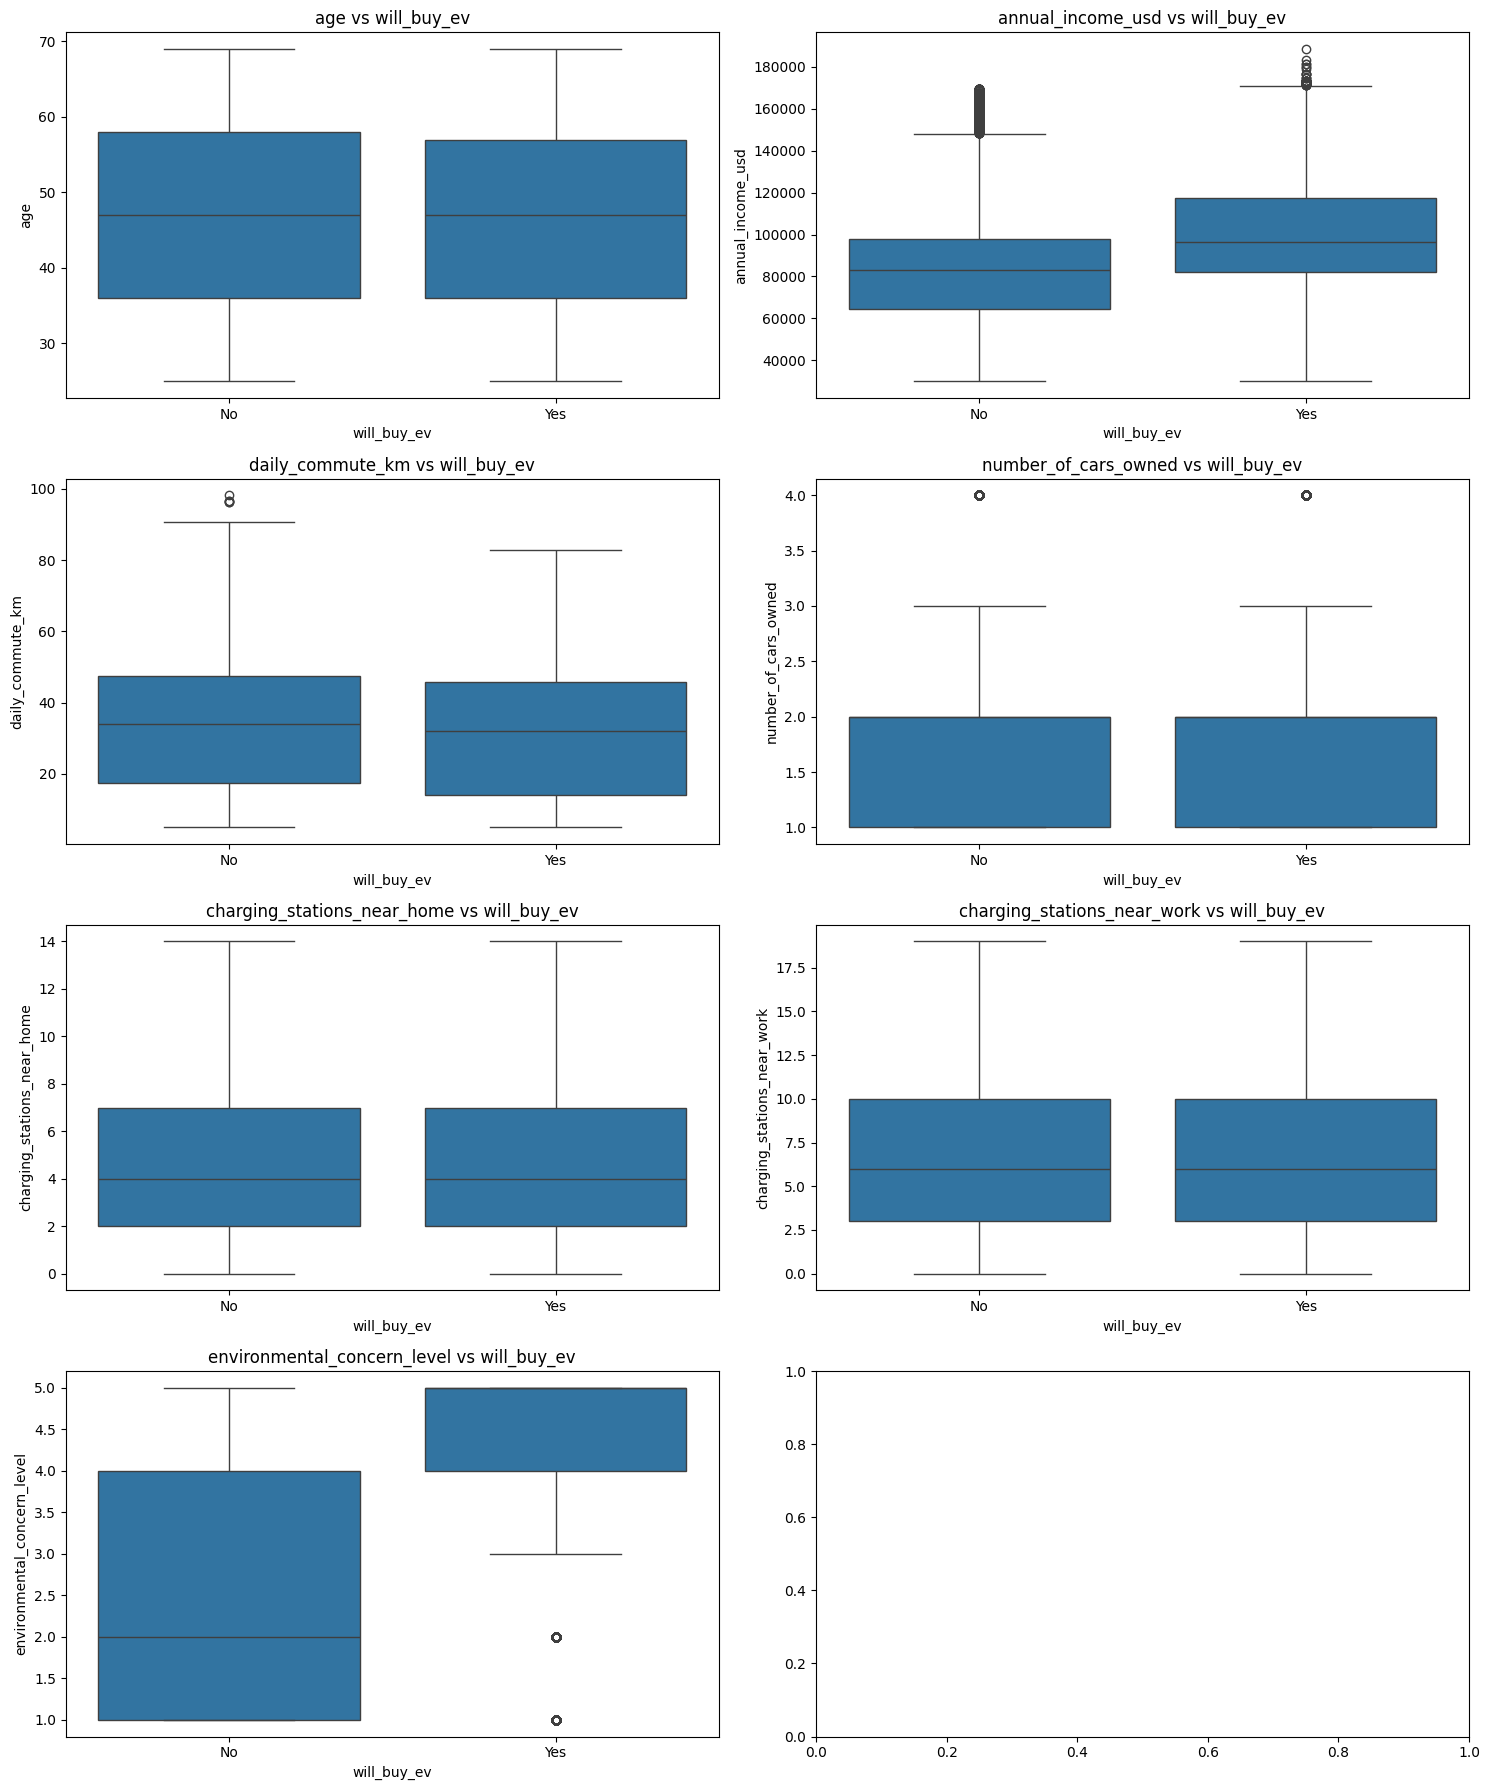

In [ ]:
fig, axes = plt.subplots(
    4,
    2,
    figsize = (15, 18)
)

for ax, col in zip(axes.flatten(), numerical):
    sns.boxplot(
        data=df,
        x='will_buy_ev',
        y=col,
        ax=ax
    )
    ax.set_title(f'{col} vs will_buy_ev')

plt.tight_layout()
plt.show()

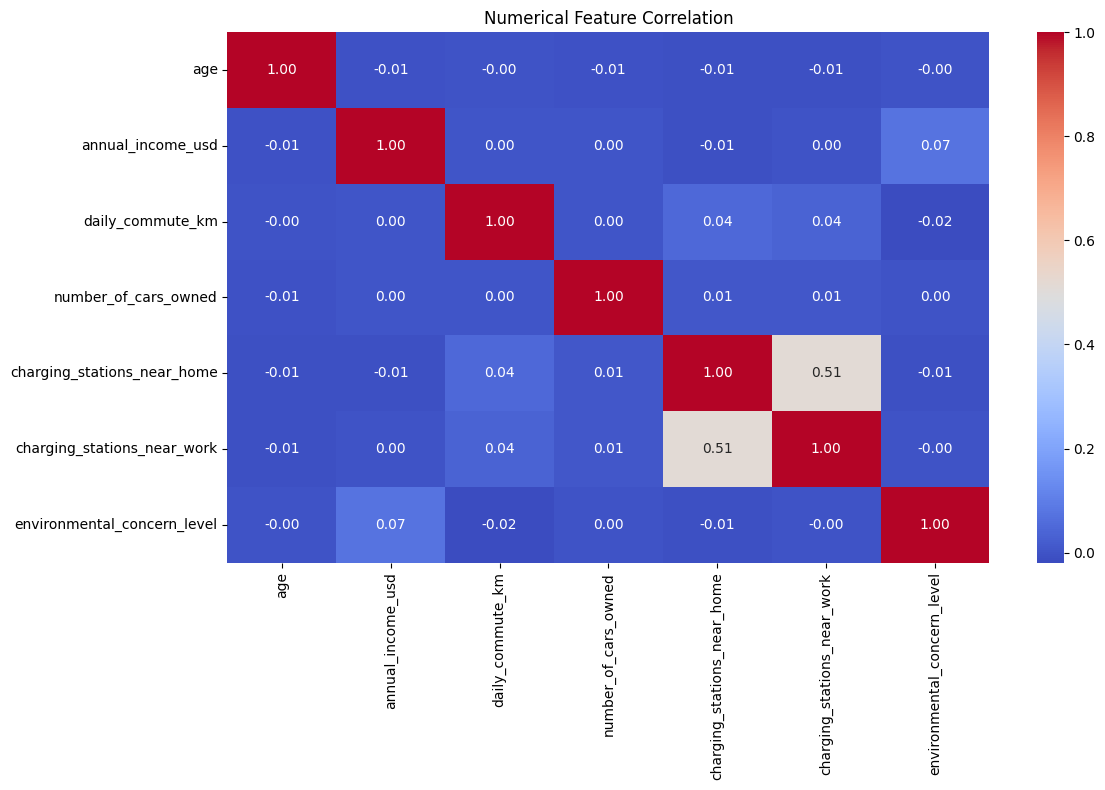

In [ ]:
correlation = df[numerical].corr()

plt.figure(figsize = (12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Numerical Feature Correlation')
plt.tight_layout()
plt.show()

In [ ]:
correlation

,age,annual_income_usd,daily_commute_km,number_of_cars_owned,charging_stations_near_home,charging_stations_near_work,environmental_concern_level
age,1.000000,-0.005627,-0.002488,-0.005244,-0.007711,-0.008227,-0.000250
annual_income_usd,-0.005627,1.000000,0.003039,0.003429,-0.008902,0.000750,0.073249
daily_commute_km,-0.002488,0.003039,1.000000,0.004701,0.044601,0.036167,-0.019112
number_of_cars_owned,-0.005244,0.003429,0.004701,1.000000,0.007272,0.008535,0.000684
charging_stations_near_home,-0.007711,-0.008902,0.044601,0.007272,1.000000,0.510885,-0.007430
charging_stations_near_work,-0.008227,0.000750,0.036167,0.008535,0.510885,1.000000,-0.001446
environmental_concern_level,-0.000250,0.073249,-0.019112,0.000684,-0.007430,-0.001446,1.000000


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique IDs:", df['id'].nunique())
print("Minimum ID:", df['id'].min())
print("Maximum ID:", df['id'].max())

Duplicate rows: 0
Unique IDs: 126802
Minimum ID: 0
Maximum ID: 126801


In [9]:
mi_score = []

for c in categorical:
    mi = mutual_info_score(df[c], df['will_buy_ev'])
    mi_score.append((c, mi))

# mi_score.sort(key=lambda x: x[1], reverse=True)
columns = ["Categorical Feature", "Mutual Information Score"]
df_mi_score = pd.DataFrame(
    mi_score,
    columns=columns
    ).sort_values(
    by="Mutual Information Score",
    ascending=False,
).reset_index(drop=True)
df_mi_score


,Categorical Feature,Mutual Information Score
0,subsidy_available,0.080822
1,range_anxiety_level,0.009025
2,home_charging_possible,0.003664
3,city_type,0.000555
4,current_car_type,0.000131
5,gender,0.000025


In [10]:
mi_score = []

for c in numerical:
    mi = mutual_info_score(df[c], df['will_buy_ev'])
    mi_score.append((c, mi))

# mi_score.sort(key=lambda x: x[1], reverse=True)
columns = ["Numerical Feature", "Mutual Information Score"]
df_mi_score = pd.DataFrame(
    mi_score,
    columns=columns
    ).sort_values(
    by="Mutual Information Score",
    ascending=False,
).reset_index(drop=True)
df_mi_score


,Numerical Feature,Mutual Information Score
0,environmental_concern_level,0.125950
1,annual_income_usd,0.062704
2,daily_commute_km,0.004965
3,age,0.002007
4,charging_stations_near_home,0.000535
5,charging_stations_near_work,0.000158
6,number_of_cars_owned,0.000041


## **Data preprocessing**

In [174]:
df_train_full, df_test = train_test_split(df, test_size = 0.2, random_state=23)
df_train, df_val = train_test_split(df_train_full, test_size = 0.25, random_state=23)

In [65]:
df_train_full.shape, df_train.shape, df_test.shape, df_val.shape

((25540, 15), (19155, 15), (6386, 15), (6385, 15))

In [66]:
df_train = df_train.reset_index(drop=True)
df_train_full = df_train_full.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [67]:
y_train = (df_train.will_buy_ev == 'Yes').astype('int').values
y_train_full = (df_train_full.will_buy_ev == 'Yes').astype('int').values
y_val = (df_val.will_buy_ev == 'Yes').astype('int').values
y_test = (df_test.will_buy_ev == 'Yes').astype('int').values

In [68]:
del df_train['will_buy_ev']
del df_train_full['will_buy_ev']
del df_val['will_buy_ev']
del df_test['will_buy_ev']

In [69]:
df_train_full.shape, df_train.shape, df_test.shape, df_val.shape

((25540, 14), (19155, 14), (6386, 14), (6385, 14))

In [80]:
X_train_full = df_train_full.to_dict(orient = "records")
X_train = df_train.to_dict(orient = "records")
X_val = df_val.to_dict(orient = "records")
X_test = df_test.to_dict(orient = "records")

In [ ]:
y_train_full.shape, y_train.shape, y_val.shape, y_test.shape

# **Model training**

## **logistic regression**

Logistic Regression	C, penalty, solver

In [70]:
def make_pipe_lr(C = 1, penalty = "l2", solver = "liblinear"):

    pipe = make_pipeline(
        DictVectorizer(sparse = False),
        SimpleImputer(strategy = "median"),
        StandardScaler(),
        LogisticRegression(
            C = C,
            max_iter = 1000,
            solver = "liblinear",
        )
    )

    return pipe

In [175]:
lr = make_pipe_lr(C = 1).fit(X_train, y_train)
lr


Pipeline(steps=[('dictvectorizer', DictVectorizer(sparse=False)),
                ('simpleimputer', SimpleImputer(strategy='median')),
                ('standardscaler', StandardScaler()),
                ('logisticregression',
                 LogisticRegression(C=1, max_iter=1000, solver='liblinear'))])

In [176]:
y_pred= lr.predict_proba(X_val)[:, 1]


In [177]:
y_pred

array([5.93914175e-01, 7.03950541e-01, 6.36985224e-01, ...,
       1.10627592e-04, 7.30837634e-03, 5.78212467e-01], shape=(6385,))

In [178]:
auc_train  = roc_auc_score(y_train, lr.predict_proba(X_train)[:, 1])
auc_val = roc_auc_score(y_val,   lr.predict_proba(X_val)[:, 1])

print(f"auc_train: {auc_train}")
print(f"auc_val: {auc_val}")

auc_train: 0.9406665768373074
auc_val: 0.9327206850756499


In [179]:
print("Accuracy:", accuracy_score(y_val, lr.predict(X_val)))
print("Precision:", precision_score(y_val, lr.predict(X_val)))
print("Recall:", recall_score(y_val, lr.predict(X_val)))
print("F1:", f1_score(y_val, lr.predict(X_val)))
print("ROC-AUC:", roc_auc_score(y_val, lr.predict_proba(X_val)[:, 1]))
print("Confusion Matrix:\n", confusion_matrix(y_val, lr.predict(X_val)))

Accuracy: 0.8908379013312451
Precision: 0.7044989775051125
Recall: 0.6280765724703737
F1: 0.6640963855421687
ROC-AUC: 0.9327206850756499
Confusion Matrix:
 [[4999  289]
 [ 408  689]]


In [180]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)
rate_df = pd.DataFrame(
    {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds.round(2)
    }
)
rate_df.head()

,fpr,tpr,thresholds
0,0.000000,0.000000,inf
1,0.000000,0.000912,0.96
2,0.000000,0.004558,0.95
3,0.000189,0.004558,0.94
4,0.000189,0.019143,0.93


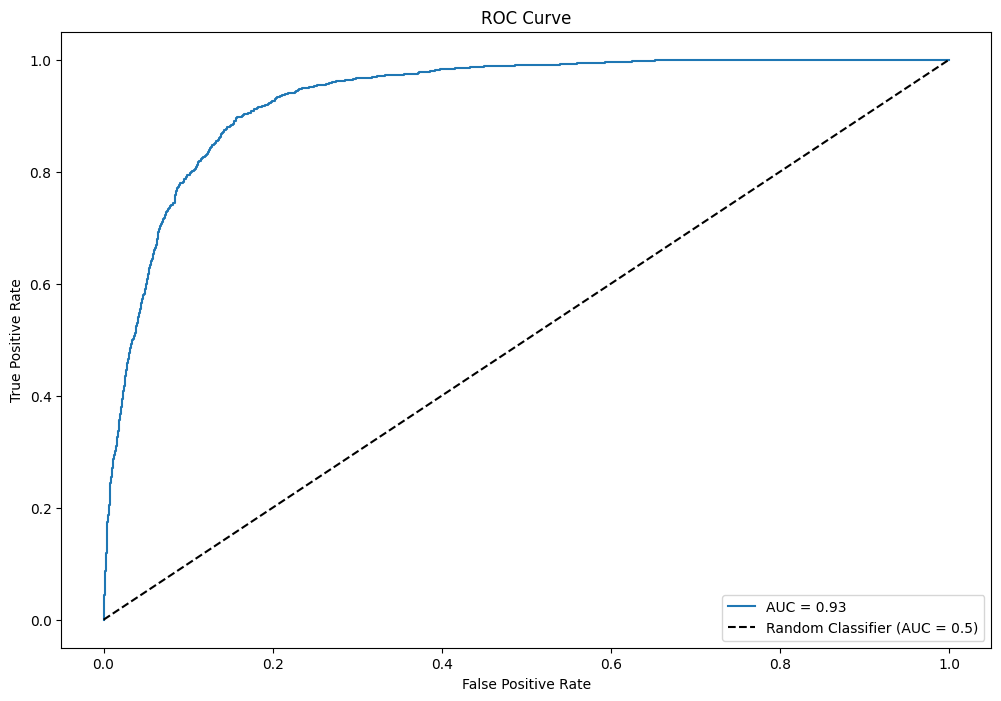

In [181]:
plt.figure(figsize = (12, 8))

plt.plot(rate_df.fpr, rate_df.tpr, label = f"AUC = {roc_auc_score(y_val, y_pred):.2f}")
plt.plot([0, 1], [0, 1], 'k--', label = "Random Classifier (AUC = 0.5)")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## **Decision tree**

Decision Tree	max_depth, min_samples_split, min_samples_leaf, criterion

In [71]:
def make_pipe_dt(
        max_depth = None,
        min_samples_split = 2,
        min_samples_leaf = 1,
        criterion = "gini"):

    pipe = make_pipeline(
        DictVectorizer(sparse = False),
        SimpleImputer(strategy = "median"),
        # StandardScaler(),
        DecisionTreeClassifier(
            max_depth = max_depth,
            min_samples_split = min_samples_split,
            min_samples_leaf = min_samples_leaf,
            criterion = criterion,
            random_state = 23
        )
    )

    return pipe

In [182]:
dt = make_pipe_dt(
    max_depth = 5,
    min_samples_split = 10).fit(X_train, y_train)
dt

Pipeline(steps=[('dictvectorizer', DictVectorizer(sparse=False)),
                ('simpleimputer', SimpleImputer(strategy='median')),
                ('decisiontreeclassifier',
                 DecisionTreeClassifier(max_depth=5, min_samples_split=10,
                                        random_state=23))])

In [183]:
y_pred = dt.predict_proba(X_val)[:, 1]
auc_train  = roc_auc_score(y_train, dt.predict_proba(X_train)[:, 1])
auc_val = roc_auc_score(y_val, y_pred)

print(f"auc_train: {auc_train}")
print(f"auc_val: {auc_val}")

auc_train: 0.9372976270303857
auc_val: 0.924489341030482


In [184]:

print("Accuracy:", accuracy_score(y_val, dt.predict(X_val)))
print("Precision:", precision_score(y_val, dt.predict(X_val)))
print("Recall:", recall_score(y_val, dt.predict(X_val)))
print("F1:", f1_score(y_val, dt.predict(X_val)))
print("ROC-AUC:", roc_auc_score(y_val, dt.predict_proba(X_val)[:, 1]))
print("Confusion Matrix:\n", confusion_matrix(y_val, dt.predict(X_val)))

Accuracy: 0.8877055599060297
Precision: 0.6635111876075731
Recall: 0.7028258887876025
F1: 0.6826029216467463
ROC-AUC: 0.924489341030482
Confusion Matrix:
 [[4897  391]
 [ 326  771]]


In [185]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

rate_df = pd.DataFrame(
    {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds.round(2)
    }
)
rate_df.head()

,fpr,tpr,thresholds
0,0.000000,0.000000,inf
1,0.000189,0.000000,1.00
2,0.006430,0.193254,0.88
3,0.031770,0.471285,0.72
4,0.073941,0.702826,0.53


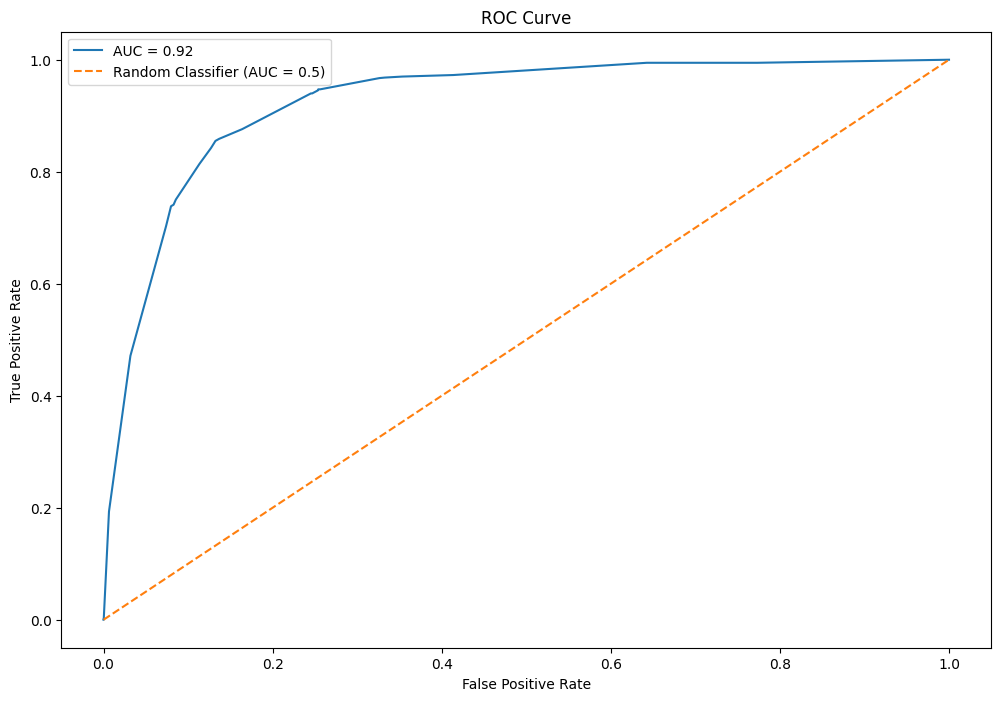

In [186]:
plt.figure(figsize = (12, 8))

plt.plot(
    rate_df.fpr,
    rate_df.tpr,
    label = f"AUC = {roc_auc_score(y_val, y_pred):.2f}"
)
plt.plot([0, 1], [0, 1], linestyle = '--', label = "Random Classifier (AUC = 0.5)")
plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.legend()
plt.show()

##	**Random Forest**


Random Forest	n_estimators, max_depth, min_samples_split, min_samples_leaf, max_features

In [72]:
def make_pipe_rf(
        n_estimators = 100,
        max_depth = None,
        min_samples_split = 2,
        min_samples_leaf = 10):
    pipe = make_pipeline(
        DictVectorizer(sparse = False),
        SimpleImputer(strategy = "median"),
        RandomForestClassifier(
            n_estimators = n_estimators,
            max_depth = max_depth,
            min_samples_split = min_samples_split,
            min_samples_leaf = min_samples_leaf,
            random_state = 23,
            n_jobs = -1
        )
    )
    return pipe

In [187]:
rf = make_pipe_rf(
    n_estimators = 100,
    max_depth = 5,
    min_samples_split = 10).fit(X_train, y_train)

rf

Pipeline(steps=[('dictvectorizer', DictVectorizer(sparse=False)),
                ('simpleimputer', SimpleImputer(strategy='median')),
                ('randomforestclassifier',
                 RandomForestClassifier(max_depth=5, min_samples_leaf=10,
                                        min_samples_split=10, n_jobs=-1,
                                        random_state=23))])

In [188]:
y_pred = rf.predict_proba(X_val)[:, 1]
auc_train  = roc_auc_score(y_train, rf.predict_proba(X_train)[:, 1])
auc_val = roc_auc_score(y_val, y_pred)

print(f"auc_train: {auc_train}")
print(f"auc_val: {auc_val}")

auc_train: 0.9367381451172557
auc_val: 0.9252044842418535


In [189]:
print("Accuracy:", accuracy_score(y_val, rf.predict(X_val)))
print("Precision:", precision_score(y_val, rf.predict(X_val)))
print("Recall:", recall_score(y_val, rf.predict(X_val)))
print("F1:", f1_score(y_val, rf.predict(X_val)))
print("ROC-AUC:", roc_auc_score(y_val, rf.predict_proba(X_val)[:, 1]))
print("Confusion Matrix:\n", confusion_matrix(y_val, rf.predict(X_val)))

Accuracy: 0.8775254502740799
Precision: 0.7911275415896488
Recall: 0.390154968094804
F1: 0.5225885225885226
ROC-AUC: 0.9252044842418535
Confusion Matrix:
 [[5175  113]
 [ 669  428]]


In [190]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

rate_df = pd.DataFrame(
    {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds.round(2)
    }
)
rate_df.head()

,fpr,tpr,thresholds
0,0.000000,0.000000,inf
1,0.000000,0.000912,0.61
2,0.000000,0.011851,0.61
3,0.000189,0.011851,0.61
4,0.000189,0.013674,0.61


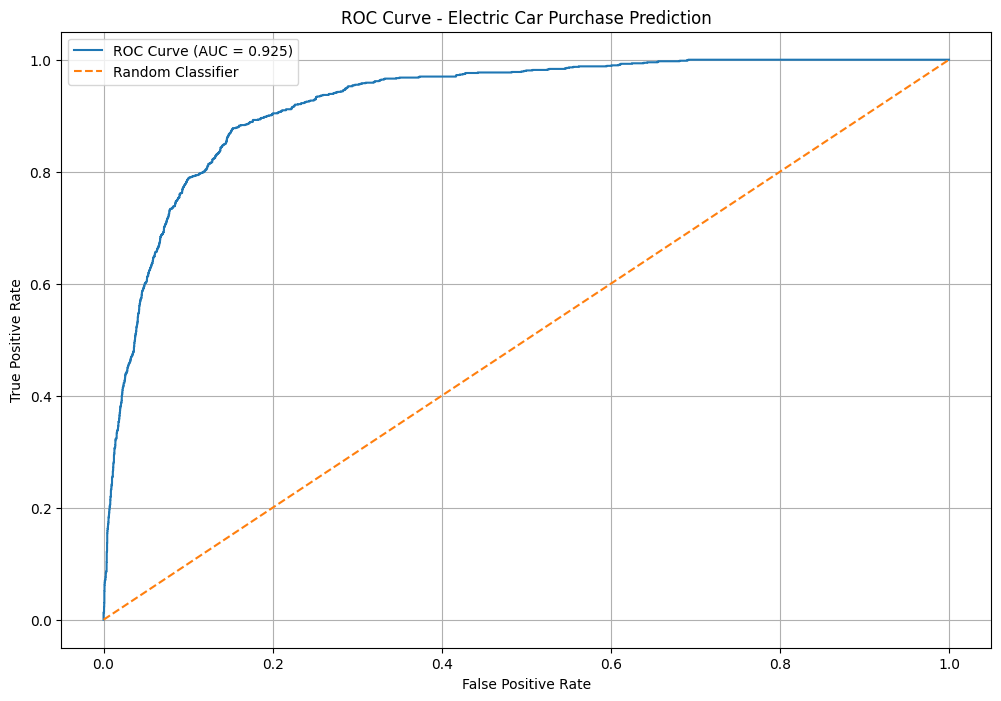

In [191]:
auc = roc_auc_score(y_val, y_pred)

plt.figure(figsize=(12, 8))

plt.plot(rate_df.fpr, rate_df.tpr, label=f'ROC Curve (AUC = {auc:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Electric Car Purchase Prediction')

plt.legend()
plt.grid()
plt.show()

##	**Extra Trees**


In [ ]:
?ExtraTreesClassifier

Extra Trees	n_estimators, max_depth, min_samples_split, min_samples_leaf, max_features


In [73]:
def make_pipe_et(
        n_estimators = 100,
        max_depth = None,
        min_samples_split = 2,
        min_samples_leaf = 10):

    pipe = make_pipeline(
        DictVectorizer(sparse = False),
        SimpleImputer(strategy = "median"),
        ExtraTreesClassifier(
            n_estimators = n_estimators,
            max_depth = max_depth,
            min_samples_split = min_samples_split,
            min_samples_leaf = min_samples_leaf,
            random_state = 23,
            n_jobs=-1
        )
    )
    return pipe

In [192]:
et = make_pipe_et(
    n_estimators = 100,
    max_depth = 5,
    min_samples_split = 10).fit(X_train, y_train)

et

Pipeline(steps=[('dictvectorizer', DictVectorizer(sparse=False)),
                ('simpleimputer', SimpleImputer(strategy='median')),
                ('extratreesclassifier',
                 ExtraTreesClassifier(max_depth=5, min_samples_leaf=10,
                                      min_samples_split=10, n_jobs=-1,
                                      random_state=23))])

In [193]:
y_pred = et.predict_proba(X_val)[:, 1]
auc_train  = roc_auc_score(y_train, et.predict_proba(X_train)[:, 1])
auc_val = roc_auc_score(y_val, y_pred)

print(f"auc_train: {auc_train}")
print(f"auc_val: {auc_val}")

auc_train: 0.9341773295662323
auc_val: 0.9259002340311977


In [194]:
print("Accuracy:", accuracy_score(y_val, et.predict(X_val)))
print("Precision:", precision_score(y_val, et.predict(X_val)))
print("Recall:", recall_score(y_val, et.predict(X_val)))
print("F1:", f1_score(y_val, et.predict(X_val)))
print("ROC-AUC:", roc_auc_score(y_val, et.predict_proba(X_val)[:, 1]))
print("Confusion Matrix:\n", confusion_matrix(y_val, et.predict(X_val)))

Accuracy: 0.8332028191072827
Precision: 0.9210526315789473
Recall: 0.03190519598906107
F1: 0.06167400881057269
ROC-AUC: 0.9259002340311977
Confusion Matrix:
 [[5285    3]
 [1062   35]]


In [195]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

rate_df = pd.DataFrame(
    {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds.round(2)
    }
)
rate_df.head()

,fpr,tpr,thresholds
0,0.000000,0.000000,inf
1,0.000000,0.000912,0.53
2,0.000000,0.004558,0.52
3,0.000189,0.004558,0.52
4,0.000189,0.028259,0.50


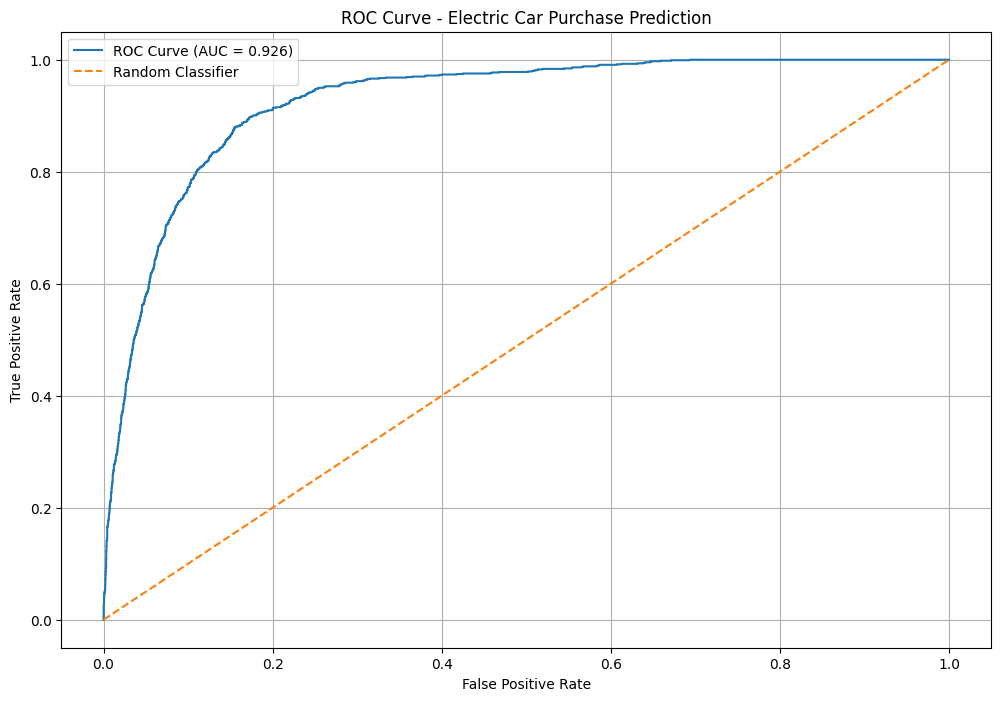

In [196]:
auc = roc_auc_score(y_val, y_pred)

plt.figure(figsize=(12, 8))

plt.plot(rate_df.fpr, rate_df.tpr, label=f'ROC Curve (AUC = {auc:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Electric Car Purchase Prediction')

plt.legend()
plt.grid()
plt.show()

##	**XGBoost	Gradient**


XGBoost	n_estimators, max_depth, learning_rate, subsample, colsample_bytree

In [74]:
def make_pipe_xgb(
        n_estimators = 100,
        max_depth = None,
        learning_rate = 0.1):

    pipe = make_pipeline(
        DictVectorizer(sparse = False),
        SimpleImputer(strategy = "median"),
        XGBClassifier(
            n_estimators = n_estimators,
            max_depth = max_depth,
            learning_rate = learning_rate,
            random_state = 23,
            eval_metric='auc',
            n_jobs=-1
        )

    )
    return pipe

In [197]:
xgb = make_pipe_xgb(
    n_estimators = 100,
    max_depth = 5,
    learning_rate = 0.1).fit(X_train, y_train)

xgb

Pipeline(steps=[('dictvectorizer', DictVectorizer(sparse=False)),
                ('simpleimputer', SimpleImputer(strategy='median')),
                ('xgbclassifier',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None,
                               early_stopping_rounds=None,
                               enable_categorical=True, eval_metric='auc',
                               feature_type...ghts=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [198]:
y_pred = xgb.predict_proba(X_val)[:, 1]
auc_train  = roc_auc_score(y_train, xgb.predict_proba(X_train)[:, 1])
auc_val = roc_auc_score(y_val, y_pred)

print(f"auc_train: {auc_train}")
print(f"auc_val: {auc_val}")

auc_train: 0.9585446651976434
auc_val: 0.9326953443375345


In [199]:
print("Accuracy:", accuracy_score(y_val, xgb.predict(X_val)))
print("Precision:", precision_score(y_val, xgb.predict(X_val)))
print("Recall:", recall_score(y_val, xgb.predict(X_val)))
print("F1:", f1_score(y_val, xgb.predict(X_val)))
print("ROC-AUC:", roc_auc_score(y_val, xgb.predict_proba(X_val)[:, 1]))
print("Confusion Matrix:\n", confusion_matrix(y_val, xgb.predict(X_val)))

Accuracy: 0.8930305403288958
Precision: 0.7107942973523421
Recall: 0.6362807657247037
F1: 0.6714766714766714
ROC-AUC: 0.9326953443375345
Confusion Matrix:
 [[5004  284]
 [ 399  698]]


In [200]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

rate_df = pd.DataFrame(
    {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds.round(2)
    }
)
rate_df.head()

,fpr,tpr,thresholds
0,0.000000,0.000000,inf
1,0.000000,0.000912,0.95
2,0.000000,0.012762,0.92
3,0.000189,0.012762,0.91
4,0.000189,0.019143,0.91


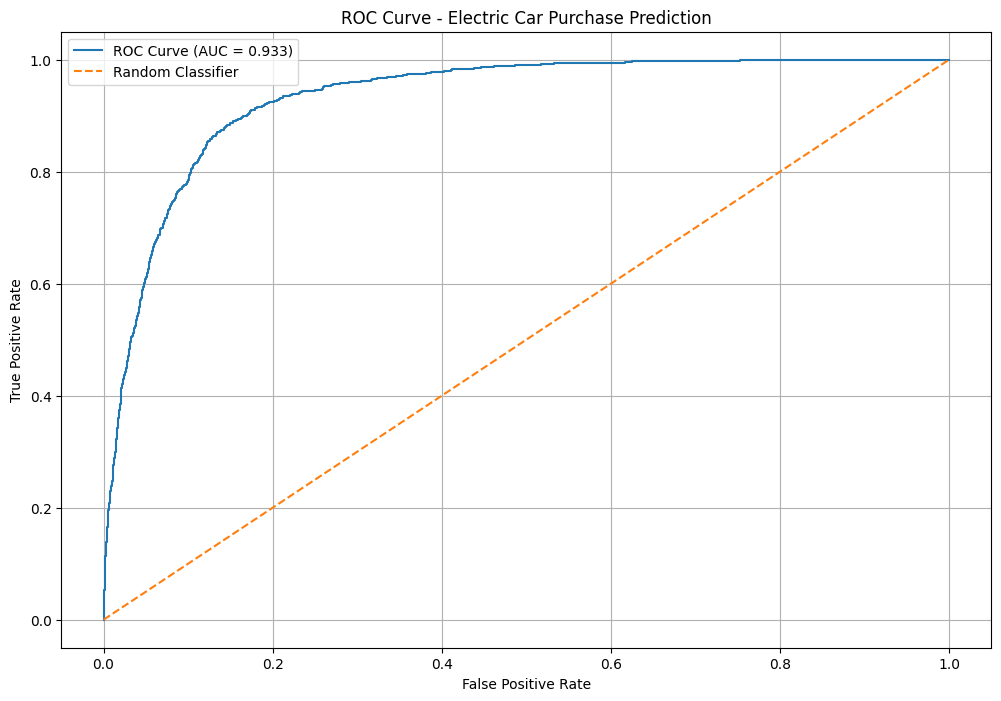

In [201]:
auc = roc_auc_score(y_val, y_pred)

plt.figure(figsize=(12, 8))

plt.plot(rate_df.fpr, rate_df.tpr, label=f'ROC Curve (AUC = {auc:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Electric Car Purchase Prediction')

plt.legend()
plt.grid()
plt.show()

##	**LightGBM**


LightGBM	n_estimators, num_leaves, max_depth, learning_rate

In [ ]:
?LGBMClassifier

In [75]:
def make_pipe_lgbm(
        n_estimators = 100,
        max_depth = None,
        num_leaves = 31,
        learning_rate = 0.1):

    pipe = make_pipeline(
        DictVectorizer(sparse = False),
        SimpleImputer(strategy = "median"),
        LGBMClassifier(
            n_estimators=n_estimators,
            max_depth=max_depth,
            learning_rate=learning_rate,
            num_leaves=num_leaves,
            random_state=42,
            n_jobs=-1
        )
    )
    return pipe


In [202]:
lgbm = make_pipe_lgbm(
    n_estimators = 100,
    max_depth = 5,
    learning_rate = 0.1,
    num_leaves = 31).fit(X_train, y_train)

lgbm

[LightGBM] [Info] Number of positive: 3357, number of negative: 15798
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.010815 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 891
[LightGBM] [Info] Number of data points in the train set: 19155, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.175255 -> initscore=-1.548836
[LightGBM] [Info] Start training from score -1.548836
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

Pipeline(steps=[('dictvectorizer', DictVectorizer(sparse=False)),
                ('simpleimputer', SimpleImputer(strategy='median')),
                ('lgbmclassifier',
                 LGBMClassifier(max_depth=5, n_jobs=-1, random_state=42))])

In [203]:
y_pred = lgbm.predict_proba(X_val)[:, 1]
auc_train  = roc_auc_score(y_train, lgbm.predict_proba(X_train)[:, 1])
auc_val = roc_auc_score(y_val, y_pred)

print(f"auc_train: {auc_train}")
print(f"auc_val: {auc_val}")

auc_train: 0.9606730308241035
auc_val: 0.931928399141104


In [204]:
print("Accuracy:", accuracy_score(y_val, lgbm.predict(X_val)))
print("Precision:", precision_score(y_val, lgbm.predict(X_val)))
print("Recall:", recall_score(y_val, lgbm.predict(X_val)))
print("F1:", f1_score(y_val, lgbm.predict(X_val)))
print("ROC-AUC:", roc_auc_score(y_val, lgbm.predict_proba(X_val)[:, 1]))
print("Confusion Matrix:\n", confusion_matrix(y_val, lgbm.predict(X_val)))

Accuracy: 0.8886452623335943
Precision: 0.700207468879668
Recall: 0.6153144940747494
F1: 0.6550218340611353
ROC-AUC: 0.931928399141104
Confusion Matrix:
 [[4999  289]
 [ 422  675]]


In [205]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

rate_df = pd.DataFrame(
    {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds.round(2)
    }
)
rate_df.head()

,fpr,tpr,thresholds
0,0.000000,0.000000,inf
1,0.000000,0.000912,0.96
2,0.000000,0.013674,0.92
3,0.000189,0.013674,0.92
4,0.000189,0.020055,0.92


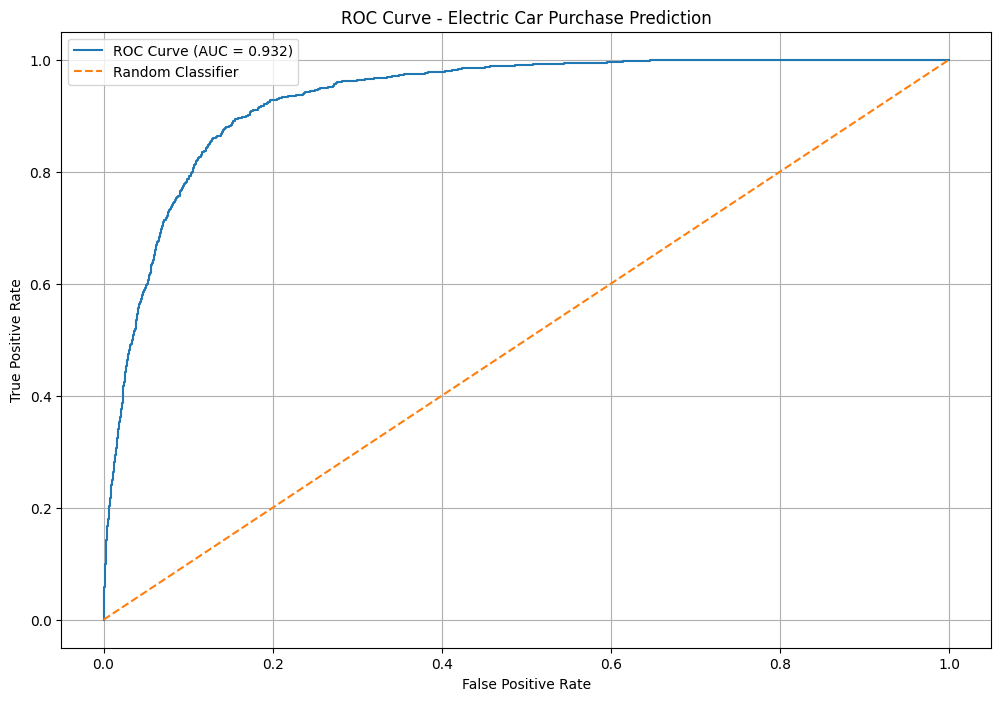

In [206]:
auc = roc_auc_score(y_val, y_pred)

plt.figure(figsize=(12, 8))

plt.plot(rate_df.fpr, rate_df.tpr, label=f'ROC Curve (AUC = {auc:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Electric Car Purchase Prediction')

plt.legend()
plt.grid()
plt.show()

##	**CatBoost**


CatBoost	iterations, depth, learning_rate, l2_leaf_reg

In [ ]:
?CatBoostClassifier

In [76]:
def make_pipe_cb(
        iterations = 100,
        depth = 6,
        learning_rate = 0.1,
        l2_leaf_reg = 3):

    pipe = make_pipeline(
        DictVectorizer(sparse = False),
        SimpleImputer(strategy = "median"),
        CatBoostClassifier(
            iterations=iterations,
            depth=depth,
            learning_rate=learning_rate,
            l2_leaf_reg=l2_leaf_reg,
            random_seed=42,
        )
    )

    return pipe

In [207]:
cb = make_pipe_cb(
    iterations = 100,
    depth = 5,
    learning_rate = 0.1,
    l2_leaf_reg = 3).fit(X_train, y_train)

cb

0:	learn: 0.5438492	total: 25.8ms	remaining: 2.55s
1:	learn: 0.4526246	total: 33.7ms	remaining: 1.65s
2:	learn: 0.3871567	total: 41.3ms	remaining: 1.33s
3:	learn: 0.3464231	total: 48.7ms	remaining: 1.17s
4:	learn: 0.3188456	total: 55.6ms	remaining: 1.06s
5:	learn: 0.2996504	total: 62.7ms	remaining: 982ms
6:	learn: 0.2831057	total: 69.5ms	remaining: 923ms
7:	learn: 0.2725452	total: 76.6ms	remaining: 881ms
8:	learn: 0.2626342	total: 83.6ms	remaining: 845ms
9:	learn: 0.2553583	total: 90.6ms	remaining: 816ms
10:	learn: 0.2499625	total: 97.7ms	remaining: 790ms
11:	learn: 0.2472731	total: 105ms	remaining: 767ms
12:	learn: 0.2450706	total: 112ms	remaining: 747ms
13:	learn: 0.2425576	total: 119ms	remaining: 729ms
14:	learn: 0.2407288	total: 126ms	remaining: 714ms
15:	learn: 0.2390589	total: 133ms	remaining: 698ms
16:	learn: 0.2369037	total: 140ms	remaining: 683ms
17:	learn: 0.2354924	total: 147ms	remaining: 669ms
18:	learn: 0.2338946	total: 154ms	remaining: 655ms
19:	learn: 0.2331648	total: 16

Pipeline(steps=[('dictvectorizer', DictVectorizer(sparse=False)),
                ('simpleimputer', SimpleImputer(strategy='median')),
                ('catboostclassifier',
                 CatBoostClassifier(depth=5, iterations=100, l2_leaf_reg=3, learning_rate=0.1, random_seed=42))])

In [208]:
y_pred = cb.predict_proba(X_val)[:, 1]
auc_train  = roc_auc_score(y_train, cb.predict_proba(X_train)[:, 1])
auc_val = roc_auc_score(y_val, y_pred)

print(f"auc_train: {auc_train}")
print(f"auc_val: {auc_val}")

auc_train: 0.9484689656722497
auc_val: 0.932999777966866


In [209]:
print("Accuracy:", accuracy_score(y_val, cb.predict(X_val)))
print("Precision:", precision_score(y_val, cb.predict(X_val)))
print("Recall:", recall_score(y_val, cb.predict(X_val)))
print("F1:", f1_score(y_val, cb.predict(X_val)))
print("ROC-AUC:", roc_auc_score(y_val, cb.predict_proba(X_val)[:, 1]))
print("Confusion Matrix:\n", confusion_matrix(y_val, cb.predict(X_val)))

Accuracy: 0.8914643696162882
Precision: 0.7099792099792099
Recall: 0.6226071103008204
F1: 0.6634288489558038
ROC-AUC: 0.932999777966866
Confusion Matrix:
 [[5009  279]
 [ 414  683]]


In [210]:
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

rate_df = pd.DataFrame(
    {
        "fpr": fpr,
        "tpr": tpr,
        "thresholds": thresholds.round(2)
    }
)
rate_df.head()

,fpr,tpr,thresholds
0,0.000000,0.000000,inf
1,0.000000,0.000912,0.93
2,0.000000,0.006381,0.91
3,0.000189,0.006381,0.91
4,0.000189,0.008204,0.91


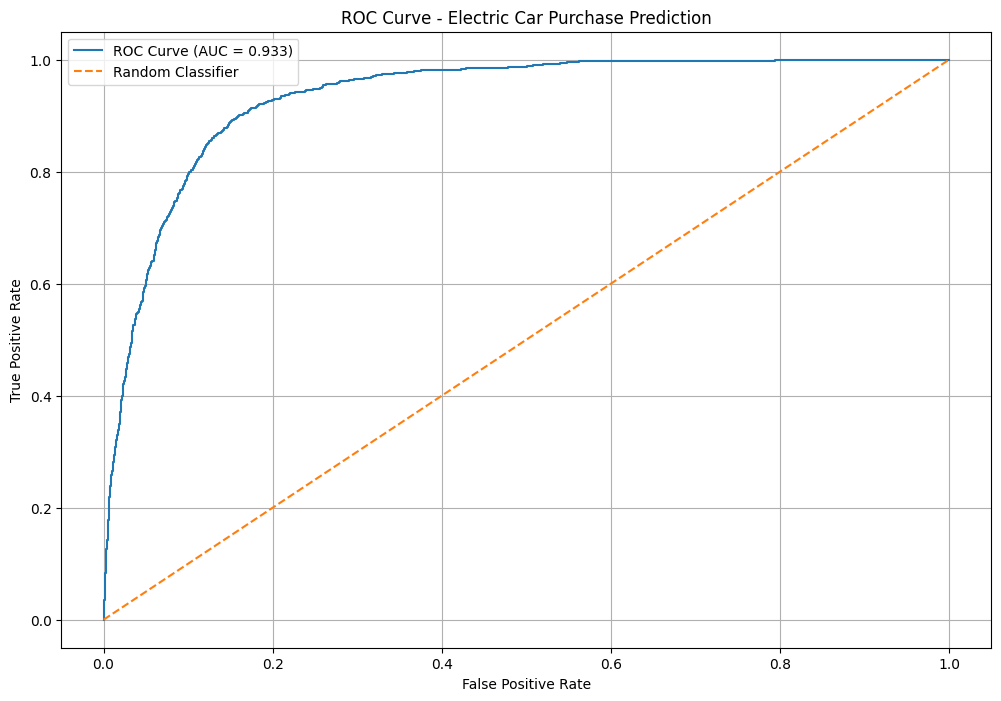

In [211]:
auc = roc_auc_score(y_val, y_pred)

plt.figure(figsize=(12, 8))

plt.plot(rate_df.fpr, rate_df.tpr, label=f'ROC Curve (AUC = {auc:.3f})')

# Random classifier reference line
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Electric Car Purchase Prediction')

plt.legend()
plt.grid()
plt.show()

## **parameter tuning**

### logistic regression

In [97]:
lr_random_search = RandomizedSearchCV(
    estimator=make_pipe_lr(),
    param_distributions={
        'logisticregression__C': [0.001, 0.01, 0.1, 1],
        'logisticregression__penalty': ['l1', 'l2'],
        'logisticregression__solver': ['liblinear']
    },
    n_iter=30,
    scoring='roc_auc',
    cv = StratifiedKFold(
        shuffle=True,
        random_state=23
    ),
    random_state=23,
    n_jobs=-1
)


In [98]:
lr_random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=23, shuffle=True),
                   estimator=Pipeline(steps=[('dictvectorizer',
                                              DictVectorizer(sparse=False)),
                                             ('simpleimputer',
                                              SimpleImputer(strategy='median')),
                                             ('standardscaler',
                                              StandardScaler()),
                                             ('logisticregression',
                                              LogisticRegression(C=1,
                                                                 max_iter=1000,
                                                                 solver='liblinear'))]),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'logisticregression__C': [0.001, 0.01,
                                                                  0.1, 1],
                                        'logisticregression__penalty': ['l1',
                                                                        'l2'],
                                        'logisticregression__solver': ['liblinear']},
                   random_state=23, scoring='roc_auc')

In [99]:
print("best parameters")
lr_random_search.best_params_

best parameters


{'logisticregression__solver': 'liblinear',
 'logisticregression__penalty': 'l1',
 'logisticregression__C': 0.1}

In [ ]:
pd.DataFrame(lr_random_search.cv_results_)[[
    'mean_fit_time',
    'mean_test_score',
    'std_test_score',
    'params' ,
    'rank_test_score',
]].sort_values(by = 'rank_test_score', ascending=True)

### decision tree

In [ ]:
?DecisionTreeClassifier

In [100]:
dt_random_search = RandomizedSearchCV(
    estimator=make_pipe_dt(),
    param_distributions={
        'decisiontreeclassifier__max_depth': [3, 10, 15, 20, 30 , 50, 100, None],
        'decisiontreeclassifier__min_samples_split': [2, 4, 7, 10, 15, 20, 30],
        'decisiontreeclassifier__min_samples_leaf': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
    },
    n_iter=30,
    scoring='roc_auc',
    cv = StratifiedKFold(
        shuffle=True,
        random_state=23
    ),
    random_state=23,
    n_jobs=-1
)


In [101]:
dt_random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=23, shuffle=True),
                   estimator=Pipeline(steps=[('dictvectorizer',
                                              DictVectorizer(sparse=False)),
                                             ('simpleimputer',
                                              SimpleImputer(strategy='median')),
                                             ('decisiontreeclassifier',
                                              DecisionTreeClassifier(random_state=23))]),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'decisiontreeclassifier__max_depth': [3,
                                                                              10,
                                                                              15,
                                                                              20,
                                                                              30,
                                                                              50,
                                                                              100,
                                                                              None],
                                        'decisiontreeclassifier__min_samples_leaf': [1,
                                                                                     2,
                                                                                     3,
                                                                                     4,
                                                                                     5,
                                                                                     6,
                                                                                     7,
                                                                                     8,
                                                                                     9,
                                                                                     10],
                                        'decisiontreeclassifier__min_samples_split': [2,
                                                                                      4,
                                                                                      7,
                                                                                      10,
                                                                                      15,
                                                                                      20,
                                                                                      30]},
                   random_state=23, scoring='roc_auc')

In [102]:
print("best parameters")
dt_random_search.best_params_

best parameters


{'decisiontreeclassifier__min_samples_split': 30,
 'decisiontreeclassifier__min_samples_leaf': 10,
 'decisiontreeclassifier__max_depth': 10}

In [ ]:
pd.DataFrame(dt_random_search.cv_results_)[[
    'mean_fit_time',
    'mean_test_score',
    'std_test_score',
    'params' ,
    'rank_test_score',
]].sort_values(by = 'rank_test_score', ascending=True)

### random forest

In [92]:
rf_random_search = RandomizedSearchCV(
    estimator=make_pipe_rf(),
    param_distributions={
        'randomforestclassifier__max_depth': [1, 2, 3, 5, 8, 10, 15, None],
        'randomforestclassifier__n_estimators': [50, 100, 200, 300, 500],
        'randomforestclassifier__min_samples_split': [2, 4, 5, 7, 9, 10],
        'randomforestclassifier__min_samples_leaf': [10, 15, 20, 30, 50]
    },
    n_iter=30,
    scoring='roc_auc',
    cv = StratifiedKFold(
        shuffle=True,
        random_state=23
    ),
    random_state=23,
    n_jobs=-1
)


In [93]:
rf_random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=23, shuffle=True),
                   estimator=Pipeline(steps=[('dictvectorizer',
                                              DictVectorizer(sparse=False)),
                                             ('simpleimputer',
                                              SimpleImputer(strategy='median')),
                                             ('randomforestclassifier',
                                              RandomForestClassifier(min_samples_leaf=10,
                                                                     n_jobs=-1,
                                                                     random_state=23))]),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'randomforestclassifier__max_depth': [1,
                                                                              2,
                                                                              3,
                                                                              5,
                                                                              8,
                                                                              10,
                                                                              15,
                                                                              None],
                                        'randomforestclassifier__min_samples_leaf': [10,
                                                                                     15,
                                                                                     20,
                                                                                     30,
                                                                                     50],
                                        'randomforestclassifier__min_samples_split': [2,
                                                                                      4,
                                                                                      5,
                                                                                      7,
                                                                                      9,
                                                                                      10],
                                        'randomforestclassifier__n_estimators': [50,
                                                                                 100,
                                                                                 200,
                                                                                 300,
                                                                                 500]},
                   random_state=23, scoring='roc_auc')

In [94]:
print("best parameters")
rf_random_search.best_params_

best parameters


{'randomforestclassifier__n_estimators': 500,
 'randomforestclassifier__min_samples_split': 5,
 'randomforestclassifier__min_samples_leaf': 15,
 'randomforestclassifier__max_depth': None}

In [95]:
pd.DataFrame(rf_random_search.cv_results_)[[
    'mean_fit_time',
    'mean_test_score',
    'std_test_score',
    'params' ,
    'rank_test_score',
]].sort_values(by = 'rank_test_score', ascending=True)

,mean_fit_time,mean_test_score,std_test_score,params,rank_test_score
18,18.046013,0.937356,0.002967,"{'randomforestclassifier__n_estimators': 500, ...",1
19,16.005492,0.937347,0.002899,"{'randomforestclassifier__n_estimators': 500, ...",2
27,17.123053,0.937331,0.003008,"{'randomforestclassifier__n_estimators': 500, ...",3
8,10.190922,0.937322,0.002824,"{'randomforestclassifier__n_estimators': 300, ...",4
1,11.853362,0.937310,0.002756,"{'randomforestclassifier__n_estimators': 300, ...",5
3,16.771656,0.937305,0.002900,"{'randomforestclassifier__n_estimators': 500, ...",6
14,10.373492,0.937295,0.003295,"{'randomforestclassifier__n_estimators': 300, ...",7
5,7.117262,0.936997,0.003103,"{'randomforestclassifier__n_estimators': 200, ...",8
4,9.679059,0.936992,0.002881,"{'randomforestclassifier__n_estimators': 300, ...",9
23,3.467098,0.936936,0.002661,"{'randomforestclassifier__n_estimators': 100, ...",10


### xgboost

In [78]:
xgb_random_search = RandomizedSearchCV(
    estimator=make_pipe_xgb(),
    param_distributions={
        'xgbclassifier__n_estimators': [50, 100, 200, 300],
        'xgbclassifier__max_depth': [3, 5, 7, 10],
        'xgbclassifier__learning_rate': [0.01, 0.05, 0.1, 0.2]
    },
    n_iter=30,
    scoring='roc_auc',
    cv = StratifiedKFold(
        shuffle=True,
        random_state=23
    ),
    random_state=23,
    n_jobs=-1
)

In [81]:
xgb_random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=23, shuffle=True),
                   estimator=Pipeline(steps=[('dictvectorizer',
                                              DictVectorizer(sparse=False)),
                                             ('simpleimputer',
                                              SimpleImputer(strategy='median')),
                                             ('xgbclassifier',
                                              XGBClassifier(base_score=None,
                                                            booster=None,
                                                            callbacks=None,
                                                            colsample_bylevel=None,
                                                            colsample_bynode=None,
                                                            colsample_bytree=None,
                                                            devi...
                                                            min_child_weight=None,
                                                            missing=nan,
                                                            monotone_constraints=None,
                                                            multi_strategy=None,
                                                            n_estimators=100,
                                                            n_jobs=-1,
                                                            num_parallel_tree=None, ...))]),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'xgbclassifier__learning_rate': [0.01,
                                                                         0.05,
                                                                         0.1,
                                                                         0.2],
                                        'xgbclassifier__max_depth': [3, 5, 7,
                                                                     10],
                                        'xgbclassifier__n_estimators': [50, 100,
                                                                        200,
                                                                        300]},
                   random_state=23, scoring='roc_auc')

In [82]:
print("best parameters")
xgb_random_search.best_params_

best parameters


{'xgbclassifier__n_estimators': 200,
 'xgbclassifier__max_depth': 3,
 'xgbclassifier__learning_rate': 0.05}

In [ ]:
pd.DataFrame(xgb_random_search.cv_results_)[[
    'mean_fit_time',
    'mean_test_score',
    'std_test_score',
    'params' ,
    'rank_test_score',
]].sort_values(by = 'rank_test_score', ascending=True)

### extra trees

In [83]:
et_random_search = RandomizedSearchCV(
    estimator=make_pipe_et(),
    param_distributions={
        'extratreesclassifier__n_estimators': [50, 100, 200],
        'extratreesclassifier__max_depth': [3, 5, 10, None],
        'extratreesclassifier__min_samples_split': [2, 5, 10],
        'extratreesclassifier__min_samples_leaf': [5, 10, 20]
    },
    n_iter=30,
    scoring='roc_auc',
    cv = StratifiedKFold(
        shuffle=True,
        random_state=23
    ),
    random_state=23,
    n_jobs=-1
)

In [84]:
et_random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=23, shuffle=True),
                   estimator=Pipeline(steps=[('dictvectorizer',
                                              DictVectorizer(sparse=False)),
                                             ('simpleimputer',
                                              SimpleImputer(strategy='median')),
                                             ('extratreesclassifier',
                                              ExtraTreesClassifier(min_samples_leaf=10,
                                                                   n_jobs=-1,
                                                                   random_state=23))]),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'extratreesclassifier__max_depth': [3,
                                                                            5,
                                                                            10,
                                                                            None],
                                        'extratreesclassifier__min_samples_leaf': [5,
                                                                                   10,
                                                                                   20],
                                        'extratreesclassifier__min_samples_split': [2,
                                                                                    5,
                                                                                    10],
                                        'extratreesclassifier__n_estimators': [50,
                                                                               100,
                                                                               200]},
                   random_state=23, scoring='roc_auc')

In [85]:
print("best parameters")
et_random_search.best_params_

best parameters


{'extratreesclassifier__n_estimators': 200,
 'extratreesclassifier__min_samples_split': 2,
 'extratreesclassifier__min_samples_leaf': 10,
 'extratreesclassifier__max_depth': None}

In [ ]:
pd.DataFrame(et_random_search.cv_results_)[[
    'mean_fit_time',
    'mean_test_score',
    'std_test_score',
    'params' ,
    'rank_test_score',
]].sort_values(by = 'rank_test_score', ascending=True)

### light gbm

In [89]:
lgbm_random_search = RandomizedSearchCV(
    estimator=make_pipe_lgbm(),
    param_distributions={
        'lgbmclassifier__n_estimators': [50, 100, 200],
        'lgbmclassifier__max_depth': [3, 5, 7, -1],
        'lgbmclassifier__num_leaves': [15, 31, 63],
        'lgbmclassifier__learning_rate': [0.01, 0.05, 0.1]
    },
    n_iter=30,
    scoring='roc_auc',
    cv = StratifiedKFold(
        shuffle=True,
        random_state=23
    ),
    random_state=23,
    n_jobs=-1
)

In [90]:
lgbm_random_search.fit(X_train, y_train)

[LightGBM] [Info] Number of positive: 3357, number of negative: 15798
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001812 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 891
[LightGBM] [Info] Number of data points in the train set: 19155, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.175255 -> initscore=-1.548836
[LightGBM] [Info] Start training from score -1.548836
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=23, shuffle=True),
                   estimator=Pipeline(steps=[('dictvectorizer',
                                              DictVectorizer(sparse=False)),
                                             ('simpleimputer',
                                              SimpleImputer(strategy='median')),
                                             ('lgbmclassifier',
                                              LGBMClassifier(max_depth=None,
                                                             n_jobs=-1,
                                                             random_state=42))]),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'lgbmclassifier__learning_rate': [0.01,
                                                                          0.05,
                                                                          0.1],
                                        'lgbmclassifier__max_depth': [3, 5, 7,
                                                                      -1],
                                        'lgbmclassifier__n_estimators': [50,
                                                                         100,
                                                                         200],
                                        'lgbmclassifier__num_leaves': [15, 31,
                                                                       63]},
                   random_state=23, scoring='roc_auc')

In [91]:
print("best parameters")
lgbm_random_search.best_params_

best parameters


{'lgbmclassifier__num_leaves': 15,
 'lgbmclassifier__n_estimators': 200,
 'lgbmclassifier__max_depth': 3,
 'lgbmclassifier__learning_rate': 0.05}

In [ ]:
pd.DataFrame(lgbm_random_search.cv_results_)[[
    'mean_fit_time',
    'mean_test_score',
    'std_test_score',
    'params' ,
    'rank_test_score',
]].sort_values(by = 'rank_test_score', ascending=True)

## catboost

In [105]:
cb_random_search = RandomizedSearchCV(
    estimator=make_pipe_cb(),
    param_distributions={
        'catboostclassifier__iterations': [50, 100, 200],
        'catboostclassifier__depth': [3, 5, 7, 10],
        'catboostclassifier__learning_rate': [0.01, 0.05, 0.1, 0.001, 1],
        'catboostclassifier__l2_leaf_reg': [1, 3, 5, 7, 9]
    },
    n_iter=30,
    scoring='roc_auc',
    cv = StratifiedKFold(
        shuffle=True,
        random_state=23
    ),
    random_state=23,
    n_jobs=-1
)



In [106]:
cb_random_search.fit(X_train, y_train)

0:	learn: 0.6156499	total: 60.9ms	remaining: 6.03s
1:	learn: 0.5556968	total: 74ms	remaining: 3.63s
2:	learn: 0.5023178	total: 92.3ms	remaining: 2.98s
3:	learn: 0.4598355	total: 109ms	remaining: 2.6s
4:	learn: 0.4261888	total: 127ms	remaining: 2.4s
5:	learn: 0.3992908	total: 139ms	remaining: 2.17s
6:	learn: 0.3765443	total: 150ms	remaining: 2s
7:	learn: 0.3572403	total: 163ms	remaining: 1.87s
8:	learn: 0.3391856	total: 174ms	remaining: 1.76s
9:	learn: 0.3242019	total: 187ms	remaining: 1.68s
10:	learn: 0.3132280	total: 199ms	remaining: 1.61s
11:	learn: 0.3052886	total: 211ms	remaining: 1.54s
12:	learn: 0.2969813	total: 223ms	remaining: 1.49s
13:	learn: 0.2899002	total: 235ms	remaining: 1.44s
14:	learn: 0.2835798	total: 247ms	remaining: 1.4s
15:	learn: 0.2783053	total: 260ms	remaining: 1.37s
16:	learn: 0.2735907	total: 276ms	remaining: 1.35s
17:	learn: 0.2685509	total: 288ms	remaining: 1.31s
18:	learn: 0.2639848	total: 300ms	remaining: 1.28s
19:	learn: 0.2599965	total: 312ms	remaining: 1

RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=23, shuffle=True),
                   estimator=Pipeline(steps=[('dictvectorizer',
                                              DictVectorizer(sparse=False)),
                                             ('simpleimputer',
                                              SimpleImputer(strategy='median')),
                                             ('catboostclassifier',
                                              CatBoostClassifier(depth=6, iterations=100, l2_leaf_reg=3, learning_rate=0.1, random_seed=42))]),
                   n_iter=30, n_jobs=-1,
                   param_distributions={'catboostclassifier__depth': [3, 5, 7,
                                                                      10],
                                        'catboostclassifier__iterations': [50,
                                                                           100,
                                                                           200],
                                        'catboostclassifier__l2_leaf_reg': [1,
                                                                            3,
                                                                            5,
                                                                            7,
                                                                            9],
                                        'catboostclassifier__learning_rate': [0.01,
                                                                              0.05,
                                                                              0.1,
                                                                              0.001,
                                                                              1]},
                   random_state=23, scoring='roc_auc')

In [107]:
cb_random_search.best_params_

{'catboostclassifier__learning_rate': 0.05,
 'catboostclassifier__l2_leaf_reg': 7,
 'catboostclassifier__iterations': 100,
 'catboostclassifier__depth': 5}

In [108]:
pd.DataFrame(cb_random_search.cv_results_)[[
    'mean_fit_time',
    'mean_test_score',
    'std_test_score',
    'params' ,
    'rank_test_score',
]].sort_values(by = 'rank_test_score', ascending=True)

,mean_fit_time,mean_test_score,std_test_score,params,rank_test_score
27,1.663219,0.940119,0.003228,"{'catboostclassifier__learning_rate': 0.05, 'c...",1
17,2.671661,0.939673,0.003288,"{'catboostclassifier__learning_rate': 0.05, 'c...",2
5,5.453859,0.939559,0.002914,"{'catboostclassifier__learning_rate': 0.01, 'c...",3
14,5.124285,0.939540,0.002955,"{'catboostclassifier__learning_rate': 0.01, 'c...",4
22,2.840840,0.939503,0.002880,"{'catboostclassifier__learning_rate': 0.01, 'c...",5
0,3.663508,0.939017,0.002908,"{'catboostclassifier__learning_rate': 0.01, 'c...",6
13,14.450089,0.938831,0.002891,"{'catboostclassifier__learning_rate': 0.01, 'c...",7
16,2.992132,0.938789,0.003486,"{'catboostclassifier__learning_rate': 0.1, 'ca...",8
9,4.733383,0.938773,0.003531,"{'catboostclassifier__learning_rate': 0.1, 'ca...",9
1,2.068470,0.938212,0.002759,"{'catboostclassifier__learning_rate': 0.01, 'c...",10


## **training final models on tuned parameters**

In [109]:
print(lr_random_search.best_params_)
print(rf_random_search.best_params_)
print(dt_random_search.best_params_)
print(et_random_search.best_params_)
print(xgb_random_search.best_params_)
print(lgbm_random_search.best_params_)
print(cb_random_search.best_params_)

{'logisticregression__solver': 'liblinear', 'logisticregression__penalty': 'l1', 'logisticregression__C': 0.1}
{'randomforestclassifier__n_estimators': 500, 'randomforestclassifier__min_samples_split': 5, 'randomforestclassifier__min_samples_leaf': 15, 'randomforestclassifier__max_depth': None}
{'decisiontreeclassifier__min_samples_split': 30, 'decisiontreeclassifier__min_samples_leaf': 10, 'decisiontreeclassifier__max_depth': 10}
{'extratreesclassifier__n_estimators': 200, 'extratreesclassifier__min_samples_split': 2, 'extratreesclassifier__min_samples_leaf': 10, 'extratreesclassifier__max_depth': None}
{'xgbclassifier__n_estimators': 200, 'xgbclassifier__max_depth': 3, 'xgbclassifier__learning_rate': 0.05}
{'lgbmclassifier__num_leaves': 15, 'lgbmclassifier__n_estimators': 200, 'lgbmclassifier__max_depth': 3, 'lgbmclassifier__learning_rate': 0.05}
{'catboostclassifier__learning_rate': 0.05, 'catboostclassifier__l2_leaf_reg': 7, 'catboostclassifier__iterations': 100, 'catboostclassifie

In [120]:
lr = make_pipe_lr(
    solver = 'liblinear',
    penalty = 'l1',
    C = 0.1
).fit(X_train, y_train)

y_pred = lr.predict_proba(X_val)[:, 1]
lr_auc_val = roc_auc_score(y_val, y_pred)
lr_auc_train = roc_auc_score(y_train, lr.predict_proba(X_train)[:, 1])

print(f"auc_val: {lr_auc_val}")


auc_val: 0.9326694864414984


In [121]:
rf = make_pipe_rf(
    max_depth = None,
    min_samples_leaf = 15,
    min_samples_split = 5,
    n_estimators = 500
).fit(X_train, y_train)

y_pred = rf.predict_proba(X_val)[:, 1]
rf_auc_val = roc_auc_score(y_val, y_pred)
print(f"auc_val: {rf_auc_val}")

auc_val: 0.929536543757766


In [122]:
dt = make_pipe_dt(
    max_depth = 10,
    min_samples_leaf = 10,
    min_samples_split = 30
).fit(X_train, y_train)

y_pred = dt.predict_proba(X_val)[:, 1]
dt_auc_val = roc_auc_score(y_val, y_pred)
print(f"auc_val: {dt_auc_val}")

auc_val: 0.9123757786674426


In [123]:
et = make_pipe_et(
    max_depth = None,
    min_samples_leaf = 10,
    min_samples_split = 2,
    n_estimators = 200
).fit(X_train, y_train)

y_pred = et.predict_proba(X_val)[:, 1]
et_auc_val = roc_auc_score(y_val, y_pred)
print(f"auc_val: {et_auc_val}")

auc_val: 0.9288649280047221


In [124]:
xgb = make_pipe_xgb(
    learning_rate = 0.05,
    max_depth = 3,
    n_estimators = 200
).fit(X_train, y_train)

y_pred = xgb.predict_proba(X_val)[:, 1]
xgb_auc_val = roc_auc_score(y_val, y_pred)
print(f"auc_val: {xgb_auc_val}")

auc_val: 0.9344151530028946


In [125]:
lgbm = make_pipe_lgbm(
    learning_rate = 0.05,
    max_depth = 3,
    num_leaves = 15,
    n_estimators = 200
).fit(X_train, y_train)

y_pred = lgbm.predict_proba(X_val)[:, 1]
lgbm_auc_val = roc_auc_score(y_val, y_pred)
print(f"auc_val: {lgbm_auc_val}")

[LightGBM] [Info] Number of positive: 3357, number of negative: 15798
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.059784 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 891
[LightGBM] [Info] Number of data points in the train set: 19155, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.175255 -> initscore=-1.548836
[LightGBM] [Info] Start training from score -1.548836
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain:

In [126]:
cb = make_pipe_cb(
    depth = 5,
    iterations = 100,
    l2_leaf_reg = 7,
    learning_rate = 0.05
).fit(X_train, y_train)

y_pred = cb.predict_proba(X_val)[:, 1]
cb_auc_val = roc_auc_score(y_val, y_pred)
print(f"auc_val: {cb_auc_val}")

0:	learn: 0.6156499	total: 13.1ms	remaining: 1.3s
1:	learn: 0.5556968	total: 24.1ms	remaining: 1.18s
2:	learn: 0.5023178	total: 34.3ms	remaining: 1.11s
3:	learn: 0.4598355	total: 49.1ms	remaining: 1.18s
4:	learn: 0.4261888	total: 62.5ms	remaining: 1.19s
5:	learn: 0.3992908	total: 74.7ms	remaining: 1.17s
6:	learn: 0.3765443	total: 99.6ms	remaining: 1.32s
7:	learn: 0.3572403	total: 113ms	remaining: 1.3s
8:	learn: 0.3391856	total: 140ms	remaining: 1.42s
9:	learn: 0.3242019	total: 159ms	remaining: 1.43s
10:	learn: 0.3132280	total: 173ms	remaining: 1.4s
11:	learn: 0.3052886	total: 187ms	remaining: 1.37s
12:	learn: 0.2969813	total: 202ms	remaining: 1.35s
13:	learn: 0.2899002	total: 215ms	remaining: 1.32s
14:	learn: 0.2835798	total: 230ms	remaining: 1.3s
15:	learn: 0.2783053	total: 243ms	remaining: 1.28s
16:	learn: 0.2735907	total: 259ms	remaining: 1.26s
17:	learn: 0.2685509	total: 270ms	remaining: 1.23s
18:	learn: 0.2639848	total: 283ms	remaining: 1.21s
19:	learn: 0.2599965	total: 294ms	rema

In [129]:
lr_auc_train = roc_auc_score(y_train, lr.predict_proba(X_train)[:, 1])
rf_auc_train = roc_auc_score(y_train, rf.predict_proba(X_train)[:, 1])
dt_auc_train = roc_auc_score(y_train, dt.predict_proba(X_train)[:, 1])
et_auc_train = roc_auc_score(y_train, et.predict_proba(X_train)[:, 1])
xgb_auc_train = roc_auc_score(y_train, xgb.predict_proba(X_train)[:, 1])
lgbm_auc_train = roc_auc_score(y_train, lgbm.predict_proba(X_train)[:, 1])
cb_auc_train = roc_auc_score(y_train, cb.predict_proba(X_train)[:, 1])


In [131]:
pd.DataFrame(
    {'model': ['lr', 'rf', 'dt', 'et', 'xgb', 'lgbm', 'cb'],
     'auc_train': [lr_auc_train, rf_auc_train, dt_auc_train, et_auc_train, xgb_auc_train, lgbm_auc_train, cb_auc_train],
     'auc_val': [lr_auc_val, rf_auc_val, dt_auc_val, et_auc_val, xgb_auc_val, lgbm_auc_val, cb_auc_val]
     }
).sort_values(by = 'auc_val', ascending = False)

,model,auc_train,auc_val
4,xgb,0.945644,0.934415
5,lgbm,0.946399,0.934368
6,cb,0.944005,0.933152
0,lr,0.940678,0.932669
1,rf,0.960694,0.929537
3,et,0.957160,0.928865
2,dt,0.957188,0.912376


In [132]:
val_predictions = {
    'Logistic Regression': lr.predict_proba(X_val)[:, 1],
    'Decision Tree': dt.predict_proba(X_val)[:, 1],
    'Random Forest': rf.predict_proba(X_val)[:, 1],
    'Extra Trees': et.predict_proba(X_val)[:, 1],
    'XGBoost': xgb.predict_proba(X_val)[:, 1],
    'LightGBM': lgbm.predict_proba(X_val)[:, 1],
    'CatBoost': cb.predict_proba(X_val)[:, 1]
}

In [139]:
for name, y_pred_proba in val_predictions.items():

    y_pred = (y_pred_proba >= 0.4).astype(int)

    print(f"\n{name}")
    print(classification_report(y_val, y_pred))


Logistic Regression
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      5288
           1       0.66      0.73      0.70      1097

    accuracy                           0.89      6385
   macro avg       0.80      0.83      0.82      6385
weighted avg       0.90      0.89      0.89      6385


Decision Tree
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      5288
           1       0.64      0.71      0.67      1097

    accuracy                           0.88      6385
   macro avg       0.79      0.82      0.80      6385
weighted avg       0.89      0.88      0.88      6385


Random Forest
              precision    recall  f1-score   support

           0       0.94      0.92      0.93      5288
           1       0.66      0.71      0.68      1097

    accuracy                           0.89      6385
   macro avg       0.80      0.81      0.81      6385
weighted avg       0.89

In [145]:
for name, y_pred_proba in val_predictions.items():

    precision, recall, thresholds = precision_recall_curve(
        y_val,
        y_pred_proba
    )

    print(f"\n{name}")
    print("Precision:", precision[:5])
    print("Recall:", recall[:5])
    print("thresholds:", thresholds[:5])


Logistic Regression
Precision: [0.17180893 0.17183584 0.17186276 0.17188969 0.17191663]
Recall: [1. 1. 1. 1. 1.]
thresholds: [1.33406446e-06 1.72198741e-06 2.21705155e-06 2.77967300e-06
 2.87222695e-06]

Decision Tree
Precision: [0.17180893 0.33176839 0.3558241  0.3709564  0.37571839]
Recall: [1.         0.96627165 0.96627165 0.96171376 0.95350957]
thresholds: [0.         0.00447761 0.0045045  0.00735294 0.00813008]

Random Forest
Precision: [0.17180893 0.17183584 0.17186276 0.17188969 0.17191663]
Recall: [1. 1. 1. 1. 1.]
thresholds: [9.66183575e-06 1.64922224e-05 9.12774769e-05 1.10145401e-04
 1.14964755e-04]

Extra Trees
Precision: [0.17180893 0.17188969 0.17207843 0.17210543 0.17213243]
Recall: [1. 1. 1. 1. 1.]
thresholds: [0.00000000e+00 9.82318271e-06 1.58040440e-05 2.18340611e-05
 2.63424872e-05]

XGBoost
Precision: [0.17180893 0.17183584 0.17186276 0.17188969 0.17191663]
Recall: [1. 1. 1. 1. 1.]
thresholds: [0.00013835 0.00013836 0.00014743 0.00019282 0.00019556]

LightGBM
Prec

In [148]:
thresholds = np.arange(0.05, 1.00, 0.05)

threshold_results = []

for name, y_pred_proba in val_predictions.items():

    for threshold in thresholds:

        y_pred = (y_pred_proba >= threshold).astype(int)

        threshold_results.append({
            'model': name,
            'threshold': round(threshold, 2),
            'precision': precision_score(y_val, y_pred, zero_division=0),
            'recall': recall_score(y_val, y_pred, zero_division=0),
            'f1_score': f1_score(y_val, y_pred, zero_division=0)
        })

threshold_df = pd.DataFrame(threshold_results)

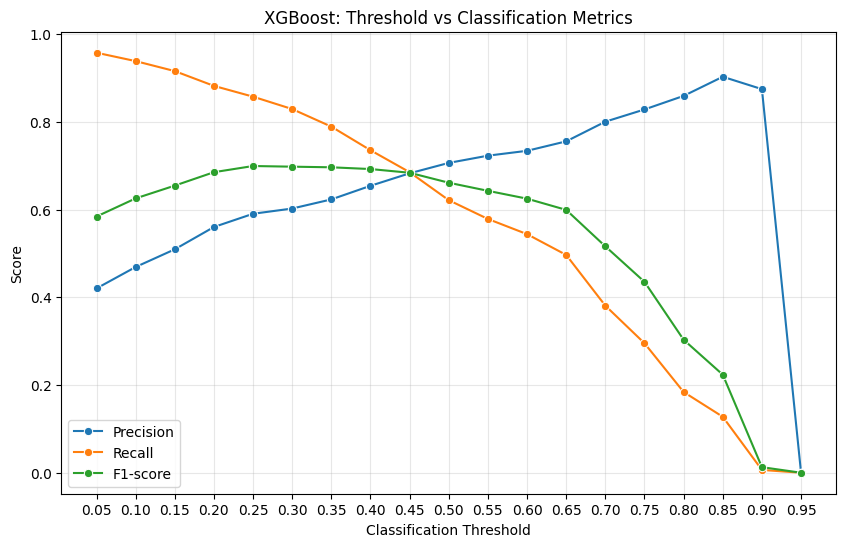

In [149]:
xgb_results = threshold_df[
    threshold_df['model'] == 'XGBoost'
]

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=xgb_results,
    x='threshold',
    y='precision',
    marker='o',
    label='Precision'
)

sns.lineplot(
    data=xgb_results,
    x='threshold',
    y='recall',
    marker='o',
    label='Recall'
)

sns.lineplot(
    data=xgb_results,
    x='threshold',
    y='f1_score',
    marker='o',
    label='F1-score'
)

plt.title('XGBoost: Threshold vs Classification Metrics')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.xticks(thresholds)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [151]:
thresholds = np.arange(0.20, 0.51, 0.01)

xgb_threshold_results = []

for threshold in thresholds:

    y_pred = (val_predictions['XGBoost'] >= threshold).astype(int)

    xgb_threshold_results.append({
        'threshold': round(threshold, 2),
        'precision': precision_score(y_val, y_pred, zero_division=0),
        'recall': recall_score(y_val, y_pred, zero_division=0),
        'f1_score': f1_score(y_val, y_pred, zero_division=0)
    })

xgb_threshold_df = pd.DataFrame(xgb_threshold_results)

xgb_threshold_df.sort_values(
    'f1_score',
    ascending=False
).head(30)

,threshold,precision,recall,f1_score
11,0.31,0.608317,0.826800,0.700927
7,0.27,0.595284,0.851413,0.700675
6,0.26,0.593295,0.855059,0.700523
9,0.29,0.600522,0.838651,0.699886
5,0.25,0.590709,0.857794,0.699628
12,0.32,0.611757,0.815861,0.699219
8,0.28,0.596129,0.842297,0.698149
10,0.30,0.602649,0.829535,0.698120
4,0.24,0.586592,0.861440,0.697932
16,0.36,0.629875,0.780310,0.697068


In [158]:
thresholds = np.arange(0.20, 0.51, 0.01)

lgbm_threshold_results = []

for threshold in thresholds:

    y_pred = (val_predictions['Random Forest'] >= threshold).astype(int)

    lgbm_threshold_results.append({
        'threshold': round(threshold, 2),
        'precision': precision_score(y_val, y_pred, zero_division=0),
        'recall': recall_score(y_val, y_pred, zero_division=0),
        'f1_score': f1_score(y_val, y_pred, zero_division=0)
    })

lgbm_threshold_df = pd.DataFrame(lgbm_threshold_results)

lgbm_threshold_df.sort_values(
    'f1_score',
    ascending=False
).head(10)

,threshold,precision,recall,f1_score
12,0.32,0.624103,0.793072,0.698515
10,0.30,0.611417,0.810392,0.696982
14,0.34,0.633308,0.773017,0.696223
11,0.31,0.616304,0.799453,0.696032
17,0.37,0.650040,0.748405,0.695763
16,0.36,0.643910,0.756609,0.695725
13,0.33,0.628403,0.778487,0.695440
15,0.35,0.637262,0.763902,0.694859
9,0.29,0.602694,0.815861,0.693261
8,0.28,0.595535,0.826800,0.692366


In [155]:
thresholds = np.arange(0.20, 0.51, 0.01)

lgbm_threshold_results = []

for threshold in thresholds:

    y_pred = (val_predictions['LightGBM'] >= threshold).astype(int)

    lgbm_threshold_results.append({
        'threshold': round(threshold, 2),
        'precision': precision_score(y_val, y_pred, zero_division=0),
        'recall': recall_score(y_val, y_pred, zero_division=0),
        'f1_score': f1_score(y_val, y_pred, zero_division=0)
    })

lgbm_threshold_df = pd.DataFrame(lgbm_threshold_results)

lgbm_threshold_df.sort_values(
    'f1_score',
    ascending=False
).head(10)

,threshold,precision,recall,f1_score
5,0.25,0.591709,0.858706,0.700632
4,0.24,0.588930,0.863263,0.700185
6,0.26,0.593532,0.853236,0.700075
7,0.27,0.595649,0.848678,0.700000
9,0.29,0.599478,0.837739,0.698859
15,0.35,0.624640,0.790337,0.697787
8,0.28,0.596889,0.839562,0.697727
14,0.34,0.619688,0.797630,0.697489
11,0.31,0.606061,0.820419,0.697134
12,0.32,0.609556,0.814038,0.697112


In [156]:
thresholds = np.arange(0.20, 0.51, 0.01)

lgbm_threshold_results = []

for threshold in thresholds:

    y_pred = (val_predictions['CatBoost'] >= threshold).astype(int)

    lgbm_threshold_results.append({
        'threshold': round(threshold, 2),
        'precision': precision_score(y_val, y_pred, zero_division=0),
        'recall': recall_score(y_val, y_pred, zero_division=0),
        'f1_score': f1_score(y_val, y_pred, zero_division=0)
    })

lgbm_threshold_df = pd.DataFrame(lgbm_threshold_results)

lgbm_threshold_df.sort_values(
    'f1_score',
    ascending=False
).head(10)

,threshold,precision,recall,f1_score
18,0.38,0.657165,0.756609,0.703390
17,0.37,0.646201,0.767548,0.701667
16,0.36,0.632353,0.783956,0.700041
15,0.35,0.623748,0.794895,0.698998
6,0.26,0.589566,0.855059,0.697917
12,0.32,0.607989,0.818596,0.697747
7,0.27,0.591746,0.849590,0.697605
14,0.34,0.615492,0.804011,0.697233
19,0.39,0.662562,0.735643,0.697192
13,0.33,0.610844,0.811304,0.696946


In [157]:
thresholds = np.arange(0.20, 0.51, 0.01)

lgbm_threshold_results = []

for threshold in thresholds:

    y_pred = (val_predictions['Logistic Regression'] >= threshold).astype(int)

    lgbm_threshold_results.append({
        'threshold': round(threshold, 2),
        'precision': precision_score(y_val, y_pred, zero_division=0),
        'recall': recall_score(y_val, y_pred, zero_division=0),
        'f1_score': f1_score(y_val, y_pred, zero_division=0)
    })

lgbm_threshold_df = pd.DataFrame(lgbm_threshold_results)

lgbm_threshold_df.sort_values(
    'f1_score',
    ascending=False
).head(10)

,threshold,precision,recall,f1_score
16,0.36,0.644106,0.772106,0.702322
17,0.37,0.648607,0.763902,0.701549
14,0.34,0.629927,0.786691,0.699635
15,0.35,0.634273,0.779398,0.699387
13,0.33,0.622413,0.794895,0.698159
21,0.41,0.669740,0.728350,0.697817
20,0.40,0.663921,0.734731,0.697534
18,0.38,0.648542,0.750228,0.695689
19,0.39,0.653537,0.741112,0.694575
22,0.42,0.672945,0.716500,0.694040


In [162]:
best_thresholds = {
    'XGBoost': 0.31,
    'Random Forest': 0.32,
    'LightGBM': 0.27,
    'CatBoost': 0.38,
    'Logistic Regression': 0.36
}

for name, threshold in best_thresholds.items():

    y_pred = (
        val_predictions[name] >= threshold
    ).astype(int)

    cm = confusion_matrix(y_val, y_pred)

    print(f"\n{name} | Threshold: {threshold}")
    print(cm)


XGBoost | Threshold: 0.31
[[4704  584]
 [ 190  907]]

Random Forest | Threshold: 0.32
[[4764  524]
 [ 227  870]]

LightGBM | Threshold: 0.27
[[4656  632]
 [ 166  931]]

CatBoost | Threshold: 0.38
[[4855  433]
 [ 267  830]]

Logistic Regression | Threshold: 0.36
[[4820  468]
 [ 250  847]]


In [160]:
thresholds = np.arange(0.05, 0.51, 0.01)

lgbm_recall_results = []

for threshold in thresholds:

    y_pred = (
        val_predictions['LightGBM'] >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, y_pred
    ).ravel()

    lgbm_recall_results.append({
        'threshold': round(threshold, 2),
        'precision': precision_score(y_val, y_pred, zero_division=0),
        'recall': recall_score(y_val, y_pred),
        'f1_score': f1_score(y_val, y_pred),
        'false_positives': fp,
        'false_negatives': fn,
        'true_positives': tp
    })

lgbm_recall_df = pd.DataFrame(lgbm_recall_results)
lgbm_recall_df

,threshold,precision,recall,f1_score,false_positives,false_negatives,true_positives
0,0.05,0.419561,0.958067,0.583565,1454,46,1051
1,0.06,0.428397,0.957156,0.591883,1401,47,1050
2,0.07,0.435524,0.954421,0.598115,1357,50,1047
3,0.08,0.445062,0.948952,0.605937,1298,56,1041
4,0.09,0.457687,0.941659,0.615981,1224,64,1033
5,0.10,0.469434,0.938013,0.625722,1163,68,1029
6,0.11,0.478525,0.934366,0.632911,1117,72,1025
7,0.12,0.487118,0.930720,0.639524,1075,76,1021
8,0.13,0.497547,0.924339,0.646890,1024,83,1014
9,0.14,0.505258,0.919781,0.652230,988,88,1009


In [163]:
models = ['XGBoost', 'LightGBM', 'CatBoost']

recall_targets = np.arange(0.80, 0.95, 0.01)
thresholds = np.arange(0.05, 0.51, 0.01)

results = []

for model in models:

    model_results = []

    for threshold in thresholds:

        y_pred = (
            val_predictions[model] >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, y_pred, labels=[0, 1]
        ).ravel()

        precision = precision_score(
            y_val, y_pred, zero_division=0
        )

        recall = recall_score(y_val, y_pred)

        model_results.append({
            'model': model,
            'threshold': round(threshold, 2),
            'precision': precision,
            'recall': recall,
            'TP': tp,
            'TN': tn,
            'FP': fp,
            'FN': fn
        })

    model_df = pd.DataFrame(model_results)

    for target in recall_targets:

        eligible = model_df[
            model_df['recall'] >= target
        ]

        if eligible.empty:
            continue

        best = eligible.sort_values(
            'threshold',
            ascending=False
        ).iloc[0]

        results.append({
            'model': model,
            'recall_target': target,
            'best_threshold': best['threshold'],
            'precision': best['precision'],
            'recall': best['recall'],
            'TP': best['TP'],
            'TN': best['TN'],
            'FP': best['FP'],
            'FN': best['FN']
        })

comparison_df = pd.DataFrame(results)

comparison_df.round(4)

,model,recall_target,best_threshold,precision,recall,TP,TN,FP,FN
0,XGBoost,0.80,0.33,0.6121,0.8040,882,4729,559,215
1,XGBoost,0.81,0.32,0.6118,0.8159,895,4720,568,202
2,XGBoost,0.82,0.31,0.6083,0.8268,907,4704,584,190
3,XGBoost,0.83,0.29,0.6005,0.8387,920,4676,612,177
4,XGBoost,0.84,0.28,0.5961,0.8423,924,4662,626,173
5,XGBoost,0.85,0.27,0.5953,0.8514,934,4653,635,163
6,XGBoost,0.86,0.24,0.5866,0.8614,945,4622,666,152
7,XGBoost,0.87,0.21,0.5675,0.8742,959,4557,731,138
8,XGBoost,0.88,0.20,0.5605,0.8824,968,4529,759,129
9,XGBoost,0.89,0.19,0.5491,0.8915,978,4485,803,119


picking lightgbm with 0.27 threshold

## **final model - lightgbm**

In [171]:
y_test_pred = (
    lgbm.predict_proba(X_test)[:, 1] >= 0.27
).astype(int)

test_auc = roc_auc_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred)
cm = confusion_matrix(
    y_test, y_test_pred)
print(f"test_auc: {test_auc:.4f}")
print(f"test_precision: {test_precision:.4f}")
print(f"test_recall: {test_recall:.4f}")

print(f"test_f1: {test_f1:.4f}")
print(f"cm: {cm}")

test_auc: 0.8646
test_precision: 0.5881
test_recall: 0.8535
test_f1: 0.6964
cm: [[4630  657]
 [ 161  938]]
